# x50 データの回帰（CONFIG で設定、フラグの扱い・後処理つき）

- **作成者**: ImoZukushi
- **作成日**: 2026-11-03
- **目的**: `009_regression_x50.ipynb` をもとに、設定を2セル目の `CONFIG` クラスにまとめ、`irregular_flg`・
  `eliminate_flg` の扱いと、予測の後処理（上下限のクリップ・`irregular_flg` の行を0にする）を加える。
- **009 との違い**
  - ファイル名・列名・定数・パラメータは、すべて2セル目の `CONFIG` にまとめる（コードは `CONFIG.名前` で参照する）。
  - `irregular_flg`（学習・テスト。int 型の 0/1）は**特徴量として使う**（009 では使わない行を表していた）。
  - `eliminate_flg`（学習だけ。int 型の 0/1）が 1 の行は、**学習に使わない**。
  - 予測が中央に寄るのを抑える対策を選べる（既定はどれも行わない）: 目的変数の分布の裾の行への重み付け
    （`CONFIG.TAIL_QUANTILES`）、LightGBM の objective（`CONFIG.LGBM_OBJECTIVE`）、Optuna によるパラメータの
    最適化（`CONFIG.N_TRIALS`）。
  - 後処理（モデルには含めない）:
    1. 予測値を `Y_cat` ごとの上下限（`CONFIG.TARGET_BOUNDS`。既定は下限 0・上限なし）でクリップする。
    2. テストデータの `irregular_flg` が 1 の行は、予測値を強制的に 0 にする。
- **入力**（ダミー。`scripts/generate_dummy_x50.py` で作成）
  - 学習: `data/synthetic/x50/dummy_x50_train.csv`（列 `date`, `Y_cat`, `irregular_flg`, `eliminate_flg`, `Y`, `X1`〜`X50`）
  - テスト: `data/synthetic/x50/dummy_x50_test.csv`（列 `date`, `Y_cat`, `irregular_flg`, `X1`〜`X50`。目的変数なし）
- **出力**
  - 前処理済みの CSV: `data/processed/x50_regression_010/`
  - `outputs/experiments/x50_regression_010_{モデル名}/{実行日時}/`（CV スコア・予測・図・SHAP・残差解析）
  - テスト予測: `outputs/predictions/x50_regression_010_{モデル名}_{実行日時}.csv`
    （列 `ID`, `date`, `Y_cat`, `pred`。テストデータの全行。`pred` は後処理の後の値）
  - MLflow（`mlruns/`）、ログファイル `outputs/logs/`
- **用語**: 正規化は、`(x - 最小値) / (最大値 - 最小値)` で 0〜1 にそろえる変換（min-max）を指す。

In [1]:
class CONFIG:
    """このノートブックの設定（ファイル名・列名・定数・パラメータ）。ここだけを変えれば条件を切り替えられる。"""

    # --- 入力・出力（data/ と outputs/ からの相対パス） ---
    RAW_TRAIN_PATH = "synthetic/x50/dummy_x50_train.csv"  # 学習データ
    RAW_TEST_PATH = "synthetic/x50/dummy_x50_test.csv"  # テストデータ（目的変数の値なし）
    FEATURES_DIR = "processed/x50_regression_010"  # 前処理済みの CSV の出力先（data/ の下）
    PREDICTIONS_DIR = "predictions"  # テスト予測の CSV の出力先（outputs/ の下）

    # --- 列 ---
    DATE_COL = "date"  # 日付
    CAT_COL = "Y_cat"  # 目的変数のカテゴリ（Y1〜Y10）
    TARGET_COL = "Y"  # 目的変数の値
    IRREGULAR_COL = (
        "irregular_flg"  # 学習・テスト。int 型の 0/1。特徴量に使い、テストで1の行は予測を0にする
    )
    ELIMINATE_COL = "eliminate_flg"  # 学習だけ。int 型の 0/1。1の行は学習に使わない
    GROUP_COL = "year_month"  # GroupKFold のグループ（年月。例: 2022-01）
    ID_COL = "ID"  # テスト予測の CSV の連番の列
    PRED_COL = "pred"  # 予測値の列
    ACTUAL_COL = "actual"  # 正解の列

    # --- 使うデータ ---
    TARGET_CATS = None  # 使う目的変数のカテゴリ（None なら学習データの全カテゴリ）
    # 使う説明変数（None なら全部。例: ["X1", "X2", "X11"]）。
    # CSV を読み込むときに、この列だけを読む。
    # irregular_flg はこれとは別に、必ず特徴量に入れる
    FEATURE_COLS = None

    # --- 前処理 ---
    # 目的変数の変換: None（行わない）/ "log"（対数）/ "normalize"（カテゴリごとの正規化）。
    # 対数は y + TARGET_LOG_OFFSET > 0 の値にしか使えない
    # （irregular_flg が 1 の行が負の値のデータでは使えない）
    TARGET_TRANSFORM = None
    TARGET_LOG_OFFSET = 0.0
    # 説明変数のスケーリング:
    # None（行わない）/ "normalize"（正規化）/ "robust"（ロバストスケーリング）
    FEATURE_SCALING = None
    FEATURE_SCALING_COLS = (
        None  # スケーリングする説明変数（None なら irregular_flg 以外の説明変数の全部）
    )
    DATE_COMPONENTS = ["year", "month", "day", "weekday", "week"]  # 日付から取り出す成分

    # --- 後処理: 予測値の上下限（Y_cat ごと。None は制限なし） ---
    DEFAULT_TARGET_BOUNDS = (0.0, None)  # (下限, 上限)。TARGET_BOUNDS に無いカテゴリに使う
    TARGET_BOUNDS = {}  # カテゴリごとの (下限, 上限)。例: {"Y1": (0.0, 150.0), "Y2": (10.0, None)}

    # --- 予測が中央に寄るのを抑える対策（既定はどれも行わない） ---
    # 目的変数の分布の裾の行への重み付け: (下側の分位, 上側の分位)。None なら重みを付けない。
    # 例 (0.1, 0.9): カテゴリごとに、学習側の 10% 点以下と 90% 点以上の行の重みを TAIL_WEIGHT にする
    # （片側だけなら (None, 0.9) のように書く。irregular_flg が 1 の行は対象にしない）
    TAIL_QUANTILES = None
    TAIL_WEIGHT = 3.0  # 裾の行の重み（それ以外の行は 1）
    # LightGBM の objective（MODEL = "lightgbm" のとき）。
    # "regression" は二乗誤差（平均に寄りやすい）。
    # huber・quantile の alpha などは MODEL_PARAMS で渡す。
    # poisson・gamma・tweedie は負の目的変数に使えない
    LGBM_OBJECTIVE = "regression"
    MODEL_PARAMS = {}  # モデルに追加で渡すパラメータ（例: {"alpha": 0.9}）
    # Optuna によるパラメータの最適化（0 なら行わない）。目的関数は元の尺度の CV の MAE
    N_TRIALS = 0
    TUNING_TIMEOUT = None  # 探索を打ち切る秒数（None なら N_TRIALS 回まで）

    # --- 学習 ---
    MODEL = "lightgbm"  # "lightgbm" または "xgboost"
    DETAIL_TARGET = "Y1"  # 詳しい図を表示するカテゴリ
    CV_METHOD = "group"  # "group"（GroupKFold）または "timeseries"（日付で区切る時系列CV）
    N_SPLITS = 5  # GroupKFold の分割数（グループ = 年月）
    CUTOFFS = ["2023-07-01", "2024-01-01"]  # 時系列CVの検証期間の開始日
    TEST_PREDICTION = "refit_full"  # "refit_full"（全学習データで学習し直す）または "fold_mean"
    LEARNING_CURVE = False  # 学習データの量を変えた学習曲線も作るか（学習し直すので時間がかかる）
    USE_TRACKING = True  # MLflow に記録するか
    OUTPUT_ROOT = None  # 実験の出力のルート（None なら outputs/experiments）
    LOG_LEVEL = "WARNING"  # 画面に出すログのレベル（ファイル outputs/logs/ には INFO 以上を残す）

    # --- 選べる値（変えない） ---
    MODELS = ("lightgbm", "xgboost")
    TARGET_TRANSFORMS = (None, "log", "normalize")
    LGBM_OBJECTIVES = (
        "regression",
        "regression_l1",
        "huber",
        "fair",
        "quantile",
        "mape",
        "poisson",
        "gamma",
        "tweedie",
    )
    SCALERS = {
        "normalize": "feature_engineering.scaling.PandasMinMaxScaler",
        "robust": "feature_engineering.scaling.PandasRobustScaler",
    }
    MLFLOW_EXPERIMENT = "x50_forecast"

In [2]:
# papermill で CONFIG の一部を変えるときに使う（このセルに parameters タグを付けている）。
# 例: uv run papermill ... \
#     -y "{CONFIG_OVERRIDES: {TARGET_TRANSFORM: normalize, CV_METHOD: timeseries}}"
CONFIG_OVERRIDES = {}

In [3]:
unknown = [name for name in CONFIG_OVERRIDES if not hasattr(CONFIG, name)]
if unknown:
    raise ValueError(f"CONFIG に無い名前です: {unknown}")
for name, value in CONFIG_OVERRIDES.items():
    setattr(CONFIG, name, value)
if CONFIG_OVERRIDES:
    print(f"CONFIG を変更: {CONFIG_OVERRIDES}")

## 設定（`CONFIG`）の使い方

2セル目の `CONFIG` の値を書き換えて実行する。papermill で実行するときは、`CONFIG_OVERRIDES`（3セル目。parameters
タグ付き）に変えたい名前と値を渡す。

```bash
uv run papermill notebook/010_regression_x50.ipynb out.ipynb --cwd notebook \
    -y "{CONFIG_OVERRIDES: {TARGET_TRANSFORM: normalize, FEATURE_SCALING: robust, CV_METHOD: timeseries}}"
```

| 名前 | 選べる値 | 既定 |
|---|---|---|
| `TARGET_TRANSFORM` | `None`（行わない）、`"log"`（対数）、`"normalize"`（カテゴリごとの正規化） | `None` |
| `FEATURE_COLS` | 使う説明変数のリスト。`None` なら全部（`irregular_flg` は必ず使う） | `None` |
| `FEATURE_SCALING` | `None`（行わない）、`"normalize"`（正規化）、`"robust"`（ロバストスケーリング） | `None` |
| `FEATURE_SCALING_COLS` | スケーリングする説明変数のリスト。`None` なら `irregular_flg` 以外の全部 | `None` |
| `CV_METHOD` | `"group"`（GroupKFold）、`"timeseries"`（日付で区切る時系列CV） | `"group"` |
| `DEFAULT_TARGET_BOUNDS` | 後処理の (下限, 上限)。`None` は制限なし | `(0.0, None)` |
| `TARGET_BOUNDS` | カテゴリごとの (下限, 上限)。例 `{"Y1": (0.0, 150.0)}` | `{}` |
| `TAIL_QUANTILES` | 裾の行に重みを付ける分位 (下側, 上側)。例 `(0.1, 0.9)`。`None` なら付けない | `None` |
| `TAIL_WEIGHT` | 裾の行の重み | `3.0` |
| `LGBM_OBJECTIVE` | LightGBM の objective（`"regression"`、`"regression_l1"`、`"huber"`、`"quantile"` など） | `"regression"` |
| `MODEL_PARAMS` | モデルに追加で渡すパラメータ（例 `{"alpha": 0.9}`） | `{}` |
| `N_TRIALS` | Optuna の試行回数（0 なら最適化しない） | `0` |

**予測が中央に寄るとき:** 二乗誤差で学習すると、予測は平均に寄りやすい。裾の行に重みを付ける（`TAIL_QUANTILES`）、
objective を変える（`LGBM_OBJECTIVE`）、パラメータを最適化する（`N_TRIALS`）を試し、「8. CV の結果」の
「予測の広がり」で効果を確かめる。

## リークを防ぐための決まり

| 段階 | 決まり | どこで確かめるか |
|---|---|---|
| 行の選択 | 学習データの `eliminate_flg` が 1 の行は、読み込みの直後に除く。前処理の fit・学習のどちらにも入らない | 4. 前処理のリークの確認 / 予測のリークの確認 |
| `irregular_flg` | 特徴量として使う（学習・テストの両方にある、予測時点で分かる値）。欠損は欠損のままモデルに渡す。テストで 1 の行も予測し、後処理で 0 にする（欠損の行は 0 にしない） | 12. 後処理 |
| 日付の前処理 | 経過日数の基準日は学習データだけで決める | 4. 前処理のリークの確認 |
| 説明変数のスケーリング | `modeling` の Pipeline に入れ、CV の各 fold の学習側だけで fit する | `make_config` |
| 系列ID | 整数化（`PandasOrdinalEncoder`）も、各 fold の学習側だけで fit する | `make_config` |
| 目的変数の変換 | 正規化の最小値・最大値は、カテゴリごとに、各 fold の学習側だけで求める。予測は元の尺度に戻してから評価する | `train_cv` |
| 裾の重み付け | 重みを決める分位点は、カテゴリごとに、各 fold の学習側だけで求める | `tail_weights` |
| パラメータの最適化 | Optuna は学習データの CV だけで評価する（テストデータは使わない）。同じ CV で最終の評価もするので、CV の誤差は楽観的になりやすい | `tune_params` |
| 特徴量 | 系列ID・日付の特徴量・`irregular_flg`・説明変数だけ。目的変数・日付・グループ・`eliminate_flg` の列が入っていないこと | 6. 学習用データとリークの確認（`prepare`） |
| CV（GroupKFold） | グループは年月。同じ月の行は学習と検証に分かれない。検証の月より後の月も学習に使う | `prepare` |
| CV（時系列） | `CONFIG.CUTOFFS` の日付で区切る。学習は境目より前だけ | `prepare` |
| 予測 | 各行の予測は、その行の特徴量だけから行う | 予測のリークの確認 |
| 後処理 | 上下限のクリップと 0 にする処理は、モデルの予測の後に行う（モデル・CV のスコアには含めない） | 12. 後処理 |
| 欠損 | 欠損は埋めない。目的変数が欠損の行は学習・評価から除く。特徴量（説明変数・`irregular_flg`）の欠損はモデルに任せる（スケーリングも欠損を残したまま行う） | `model_frames` |

**注意:** GroupKFold の CV は、未来の月も学習に使うため、学習データより後の期間の予測より楽観的になりやすい。
時間の流れに沿って確かめたいときは `CONFIG.CV_METHOD = "timeseries"` にする。

In [4]:
import datetime as dt
import gc
import hashlib
import logging
import shutil
import sys
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# pyproject.toml を目印にリポジトリルートを探し、src/ をimportパスに追加する
# （scripts/ の関数は import せず、このノートブック内で定義する）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# ipywidgets が無い環境で tqdm が出す警告（進捗バーの表示だけの問題）は出さない
warnings.filterwarnings("ignore", message="IProgress not found")

# src/ 配下のモジュール（上でパスを追加した後にimportする必要がある）
from evaluation.residuals import (  # noqa: E402
    ResidualCorrelogramDisplay,
    plot_residuals_by_group,
    residual_summary,
)
from feature_engineering.datetime_features import (  # noqa: E402
    CyclicalFeaturesEncoder,
    DatetimeFeaturesExtractor,
    ElapsedTimeTransformer,
)
from modeling.config import ExperimentConfig  # noqa: E402
from modeling.cv import folds_to_ids  # noqa: E402
from modeling.dataset import Dataset  # noqa: E402
from modeling.evaluation import EVALUATION_DIR, save_evaluation_outputs  # noqa: E402
from modeling.experiment import (  # noqa: E402
    ExperimentResult,
    make_output_dir,
    prepare_dataset,
    save_cv_outputs,
)
from modeling.explain import compute_oof_shap, save_shap_outputs  # noqa: E402
from modeling.metrics import get_metric  # noqa: E402
from modeling.models import get_model_spec  # noqa: E402
from modeling.tasks import Task, predict  # noqa: E402
from modeling.tracking import MLflowTracker, NullTracker, Tracker  # noqa: E402
from modeling.trainer import CVResult, fit_pipeline  # noqa: E402
from util.csv_io import detect_encoding  # noqa: E402
from util.paths import data_dir, ensure_parent_dir, get_repo_root, outputs_dir  # noqa: E402
from util.plotting import add_caption, ensure_japanese_font  # noqa: E402

# pandas の表示で列を省略しすぎないようにする
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

## 関数の定義

このノートブックは `scripts/` を import せず、使う関数をここで定義する。ログ・図の部品は 004、要約は 008、
学習（`train_cv`・`run_training`）は 009 と同じ関数。列名・定数はすべて `CONFIG` から読む。

### 定数と結果の入れ物

In [5]:
logger = logging.getLogger("regression_x50_010")


class LeakageError(ValueError):
    """入力データにリークのおそれがある場合のエラー。"""


class TargetScaler:
    """目的変数の変換（行わない・対数・種類ごとの正規化）と、元の尺度に戻す処理。

    正規化の最小値・最大値は `fit` に渡した行（CV の学習側）だけから求める。

    Args:
        kind: `None` / `"log"` / `"normalize"`。
        offset: 対数の変換で `log(y + offset)` にする値。

    Raises:
        ValueError: 未対応の変換の場合。
    """

    def __init__(self, kind: str | None, offset: float = 0.0) -> None:
        if kind not in CONFIG.TARGET_TRANSFORMS:
            raise ValueError(
                f"CONFIG.TARGET_TRANSFORM は {CONFIG.TARGET_TRANSFORMS} から選んでください: {kind}"
            )
        self.kind = kind
        self.offset = offset

    def fit(self, y: np.ndarray, categories: np.ndarray) -> "TargetScaler":
        """変換に必要な値を学習する。

        Raises:
            ValueError: 対数を取れない値（`y + offset <= 0`）がある場合。
        """
        if self.kind == "log" and (y + self.offset <= 0).any():
            raise ValueError(
                "対数を取れない目的変数があります（irregular_flg が 1 の行が負の値など）。"
                "CONFIG.TARGET_TRANSFORM を None か normalize にするか、"
                "CONFIG.TARGET_LOG_OFFSET を指定してください"
            )
        if self.kind == "normalize":
            grouped = pd.Series(y).groupby(categories)
            self.low_ = grouped.min()
            # 値が1種類しかない種類は、0除算にならないよう幅を1にする
            self.span_ = (grouped.max() - self.low_).replace(0.0, 1.0)
        return self

    def transform(self, y: np.ndarray, categories: np.ndarray) -> np.ndarray:
        """モデルが学習する尺度に変換する。"""
        if self.kind == "log":
            return np.log(y + self.offset)
        if self.kind == "normalize":
            cats = pd.Series(categories)
            return (y - cats.map(self.low_).to_numpy()) / cats.map(self.span_).to_numpy()
        return y

    def inverse(self, z: np.ndarray, categories: np.ndarray) -> np.ndarray:
        """モデルの尺度の値を、元の尺度に戻す。"""
        if self.kind == "log":
            return np.exp(z) - self.offset
        if self.kind == "normalize":
            cats = pd.Series(categories)
            return z * cats.map(self.span_).to_numpy() + cats.map(self.low_).to_numpy()
        return z


@dataclass
class RegressionRun:
    """学習・予測の結果。

    Attributes:
        categories: 目的変数の種類の並び。
        dataset: 学習用データ一式。
        frame: 学習に使った行の表（`dataset.X` と同じ行順）。
        result: 実験の結果（CV の結果・出力先・MLflow の run ID）。
        predictions: テスト予測（long 型。列 `date`, `Y_cat`, `pred`）。
        oof: 学習期間の OOF 予測（long 型。列 `date`, `Y_cat`, `actual`, `pred`, `fold`）。
        target_scalers: `result.cv_result.models` と同じ並びの、目的変数の変換。
        tuning_trials: Optuna の試行の一覧（最適化しなければ None）。
    """

    categories: list[str]
    dataset: Dataset
    frame: pd.DataFrame
    result: ExperimentResult
    predictions: pd.DataFrame
    oof: pd.DataFrame
    target_scalers: list[TargetScaler]
    tuning_trials: pd.DataFrame | None = None

### ログ（004 と同じ）

In [6]:
def setup_logging(
    log_path: Path, level: int = logging.INFO, console_level: int | None = None
) -> Path:
    """画面とファイルの両方にログを出す設定をする（同じ設定を2回呼んでも重複しない）。

    Args:
        log_path: ログファイルのパス（UTF-8）。
        level: ログの出力レベル（ファイル）。
        console_level: 画面に出すログのレベル（Noneなら `level` と同じ）。画面への出力量を減らしたい
            とき（小さいインスタンスの Jupyter など）は `logging.WARNING` にする。ファイルには
            `level` 以上のログが残る。

    Returns:
        ログファイルのパス。
    """
    ensure_parent_dir(log_path)
    console_level = level if console_level is None else console_level
    root = logging.getLogger()
    root.setLevel(min(level, console_level))
    for handler in list(root.handlers):
        if getattr(handler, "_x50", False):
            root.removeHandler(handler)
            handler.close()
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(name)s: %(message)s")
    file_handler = logging.FileHandler(log_path, encoding="utf-8")
    file_handler.setLevel(level)
    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(console_level)
    handlers: list[logging.Handler] = [file_handler, console_handler]
    for handler in handlers:
        handler.setFormatter(formatter)
        handler._x50 = True  # type: ignore[attr-defined]
        root.addHandler(handler)
    # ライブラリの警告もログに残す（細かい情報ログは出さない）
    logging.captureWarnings(True)
    for name in ("matplotlib", "PIL", "shap", "urllib3", "alembic", "mlflow"):
        logging.getLogger(name).setLevel(logging.WARNING)
    return log_path


def shown(path: Path) -> str:
    """ログ・画面に出すパス（リポジトリ内ならルートからの相対パス。個人のフォルダ名を残さない）。"""
    resolved = Path(path).resolve()
    root = get_repo_root()
    return resolved.relative_to(root).as_posix() if resolved.is_relative_to(root) else str(path)


def file_digest(path: Path) -> str:
    """ファイルの SHA-256（先頭12文字）。どのデータで学習したかをログに残すために使う。"""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]


def make_tracker(enabled: bool) -> Tracker:
    """MLflow に記録する（`enabled=False` なら何も記録しない）。"""
    return MLflowTracker(CONFIG.MLFLOW_EXPERIMENT) if enabled else NullTracker()

### 読み込みとモデルに渡す表

In [7]:
def check_flag(frame: pd.DataFrame, column: str, allow_missing: bool = False) -> None:
    """フラグの列が 0 か 1 だけをとることを確かめる。

    Args:
        frame: 表。
        column: フラグの列。
        allow_missing: 欠損（NaN）を許すか。特徴量として使うフラグ（`irregular_flg`）は欠損を許し、
            欠損のままモデルに渡す（欠損があると CSV からは浮動小数の型で読まれる）。

    Raises:
        ValueError: 数値でない、0・1 以外の値がある、または欠損を許さない列に欠損がある場合。
    """
    values = frame[column]
    observed = values.dropna() if allow_missing else values
    if not pd.api.types.is_numeric_dtype(values) or not observed.isin([0, 1]).all():
        kind = "0・1・欠損" if allow_missing else "int 型の 0 か 1"
        raise ValueError(f"{column} は {kind} にしてください（{values.dtype}）")


def read_columns(path: Path, feature_cols: list[str] | None, train: bool) -> pd.DataFrame:
    """CSV から、使う列だけを読み込む（メモリを節約し、使う説明変数をここで決める）。

    学習データは `irregular_flg`・`eliminate_flg`・目的変数を、
    テストデータは `irregular_flg` を読む。

    Args:
        path: CSV のパス。
        feature_cols: 使う説明変数（None なら全部）。
        train: 学習データか。

    Raises:
        ValueError: 必要な列が CSV に無い、またはフラグが int 型の 0/1 でない場合。
    """
    encoding = detect_encoding(path)
    encoding = "utf-8-sig" if encoding == "utf-8" else encoding
    header = list(pd.read_csv(path, nrows=0, encoding=encoding).columns)
    flags = [CONFIG.IRREGULAR_COL, CONFIG.ELIMINATE_COL] if train else [CONFIG.IRREGULAR_COL]
    meta = [CONFIG.DATE_COL, CONFIG.CAT_COL, *flags, *([CONFIG.TARGET_COL] if train else [])]
    excluded = {
        CONFIG.DATE_COL,
        CONFIG.CAT_COL,
        CONFIG.IRREGULAR_COL,
        CONFIG.ELIMINATE_COL,
        CONFIG.TARGET_COL,
    }
    features = [c for c in header if c not in excluded] if feature_cols is None else feature_cols
    missing = [c for c in [*meta, *features] if c not in header]
    if missing:
        raise ValueError(f"{path.name} に列がありません: {missing}")
    frame = pd.read_csv(path, usecols=[*meta, *features], encoding=encoding)
    frame[CONFIG.DATE_COL] = pd.to_datetime(frame[CONFIG.DATE_COL], format="%Y-%m-%d")
    # irregular_flg は特徴量なので欠損を許す
    # （欠損のままモデルに渡す。後処理で 0 にするのは 1 の行だけ）
    check_flag(frame, CONFIG.IRREGULAR_COL, allow_missing=True)
    frame[CONFIG.IRREGULAR_COL] = frame[CONFIG.IRREGULAR_COL].astype("float64")
    if train:
        check_flag(frame, CONFIG.ELIMINATE_COL)
    return frame[[*meta, *features]]


def drop_eliminated(frame: pd.DataFrame) -> pd.DataFrame:
    """学習データから `eliminate_flg` が 1 の行を除き、その列も外す（学習に使わない）。"""
    return (
        frame.loc[frame[CONFIG.ELIMINATE_COL] == 0]
        .drop(columns=CONFIG.ELIMINATE_COL)
        .sort_values(CONFIG.DATE_COL, kind="stable")
        .reset_index(drop=True)
    )


def model_frames(
    train: pd.DataFrame, test: pd.DataFrame, exog_cols: list[str]
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """`prepare_dataset` に渡す学習・テストの表を作る。

    学習の表は「日付・系列ID・年月（グループ）・日付の特徴量・説明変数・目的変数」。
    目的変数が欠損の行は学習できないため除く。ラグ・移動平均は作らない。

    Returns:
        (学習の表, テストの表（目的変数なし）)。
    """
    columns = [CONFIG.DATE_COL, CONFIG.CAT_COL, *exog_cols]
    used = train[train[CONFIG.TARGET_COL].notna()]
    frame = used[columns].assign(
        **{
            CONFIG.GROUP_COL: used[CONFIG.DATE_COL].dt.strftime("%Y-%m"),
            CONFIG.TARGET_COL: used[CONFIG.TARGET_COL],
        }
    )
    return frame.reset_index(drop=True), test[columns].reset_index(drop=True)

### 実験設定

In [8]:
def make_config(
    model: str,
    feature_cols: list[str],
    cv_method: str = "group",
    n_splits: int = 5,
    cutoffs: list[str] | None = None,
    test_prediction: str = "refit_full",
    feature_scaling: str | None = None,
    scaling_cols: list[str] | None = None,
    learning_curve: bool = False,
    objective: str = "regression",
    model_params: dict | None = None,
) -> ExperimentConfig:
    """通常の回帰の実験設定を作る（`ExperimentConfig` で検証する）。

    説明変数のスケーリングは Pipeline に入れるので、CV の各 fold の学習側だけで fit される。

    Args:
        model: モデル名（`lightgbm` / `xgboost`）。
        feature_cols: 使う説明変数。
        cv_method: `group`（GroupKFold）/ `timeseries`（日付で区切る時系列CV）。
        n_splits: GroupKFold の分割数。
        cutoffs: 時系列CVの検証期間の開始日。
        test_prediction: テスト予測の作り方（`refit_full` / `fold_mean`）。
        feature_scaling: `None` / `normalize` / `robust`。
        scaling_cols: スケーリングする説明変数（None なら `feature_cols` の全部）。
        learning_curve: 学習曲線を作るか。
        objective: LightGBM の objective（`model` が `lightgbm` のときだけ使う）。
        model_params: モデルに追加で渡すパラメータ。

    Raises:
        ValueError: 未対応の値や、使わない説明変数をスケーリングの対象に指定した場合。
    """
    if model not in CONFIG.MODELS:
        raise ValueError(f"モデルは {CONFIG.MODELS} から選んでください: {model}")
    if model == "lightgbm" and objective not in CONFIG.LGBM_OBJECTIVES:
        raise ValueError(
            f"CONFIG.LGBM_OBJECTIVE は {CONFIG.LGBM_OBJECTIVES} から選んでください: {objective}"
        )
    params = {"n_estimators": 1000}
    if model == "lightgbm":
        params["objective"] = objective
    params |= model_params or {}
    if feature_scaling is not None and feature_scaling not in CONFIG.SCALERS:
        raise ValueError(
            f"CONFIG.FEATURE_SCALING は None か {list(CONFIG.SCALERS)} です: {feature_scaling}"
        )
    features = [
        {
            "class": "feature_engineering.categorical.PandasOrdinalEncoder",
            "params": {"variables": [CONFIG.CAT_COL]},
        }
    ]
    if feature_scaling is not None:
        columns = feature_cols if scaling_cols is None else scaling_cols
        unknown = sorted(set(columns) - set(feature_cols))
        if unknown:
            raise ValueError(f"使わない説明変数はスケーリングできません: {unknown}")
        features.append(
            {"class": CONFIG.SCALERS[feature_scaling], "params": {"variables": list(columns)}}
        )
    if cv_method == "group":
        cv = {"method": "group", "n_splits": n_splits}
    elif cv_method == "timeseries":
        cv = {
            "method": "time_cutoff",
            "time_column": CONFIG.DATE_COL,
            "cutoffs": list(cutoffs or []),
        }
    else:
        raise ValueError(f"CONFIG.CV_METHOD は group か timeseries です: {cv_method}")
    return ExperimentConfig.model_validate(
        {
            "name": f"x50_regression_010_{model}",
            "task": "regression",
            "data": {
                "train_path": CONFIG.RAW_TRAIN_PATH,
                "test_path": CONFIG.RAW_TEST_PATH,
                "target": CONFIG.TARGET_COL,
                "group_col": CONFIG.GROUP_COL,
                "drop_cols": [CONFIG.DATE_COL, CONFIG.GROUP_COL],
            },
            "features": features,
            "cv": cv,
            "model": {"name": model, "params": params, "early_stopping_rounds": 50},
            "metrics": ["mae", "rmse"],
            "test_prediction": test_prediction,
            "explain": {"enabled": True},
            "evaluation": {
                "enabled": True,
                "training_history": True,
                "learning_curve": {"enabled": learning_curve},
            },
            "tracking": {"experiment_name": CONFIG.MLFLOW_EXPERIMENT},
        }
    )

### 学習・後処理と確認

In [9]:
def prepare(config: ExperimentConfig, train: pd.DataFrame, test: pd.DataFrame) -> Dataset:
    """学習用データ一式を作り、リークのおそれがないことを確かめる。

    確かめること:
        - モデルの特徴量に、目的変数・ラグ・日付・グループ・`eliminate_flg` の列が無い。
        - GroupKFold: 同じ年月が学習と検証の両方に入らず、各年月は1つの fold の検証に入る。
        - 時系列CV: 各 fold の学習期間が、すべて検証期間より前にある。

    Raises:
        LeakageError: 上のいずれかを満たさない場合。
    """
    dataset = prepare_dataset(config, train, test)
    leaked = [
        c
        for c in dataset.X.columns
        if c in (CONFIG.TARGET_COL, CONFIG.DATE_COL, CONFIG.GROUP_COL, CONFIG.ELIMINATE_COL)
        or c.startswith(f"{CONFIG.TARGET_COL}_lag_")
    ]
    if leaked:
        raise LeakageError(f"モデルの特徴量に使えない列があります: {leaked}")
    groups = train[CONFIG.GROUP_COL].to_numpy()
    dates = train[CONFIG.DATE_COL]
    validated: list[str] = []
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        if config.cv.method == "group":
            shared = set(groups[train_idx]) & set(groups[valid_idx])
            if shared:
                raise LeakageError(f"fold {i}: 同じ年月が学習と検証にあります: {sorted(shared)}")
            validated += sorted(set(groups[valid_idx]))
        elif dates.iloc[train_idx].max() >= dates.iloc[valid_idx].min():
            raise LeakageError(f"fold {i}: 学習期間が検証期間より後の日を含みます")
    if config.cv.method == "group" and sorted(validated) != sorted(set(groups)):
        raise LeakageError("検証に入らない年月、または複数の fold の検証に入る年月があります")
    return dataset


def tail_weights(y: np.ndarray, categories: np.ndarray, irregular: np.ndarray) -> np.ndarray | None:
    """目的変数の分布の裾の行に重みを付ける（`CONFIG.TAIL_QUANTILES` が None なら None を返す）。

    カテゴリごとに、渡した行（CV の学習側）の分位点を求め、
    下側の分位点以下・上側の分位点以上の行の重みを
    `CONFIG.TAIL_WEIGHT` にする（それ以外は1）。`irregular_flg` が 1 の行は通常と違う値なので、
    分位点の計算にも重み付けにも使わない（重み1）。

    Raises:
        ValueError: 分位の指定が 0〜1 でない、または下側が上側以上の場合。
    """
    if CONFIG.TAIL_QUANTILES is None:
        return None
    low_q, high_q = CONFIG.TAIL_QUANTILES
    for q in (low_q, high_q):
        if q is not None and not 0 <= q <= 1:
            raise ValueError(
                f"CONFIG.TAIL_QUANTILES は 0〜1 で指定してください: {CONFIG.TAIL_QUANTILES}"
            )
    if low_q is not None and high_q is not None and low_q >= high_q:
        raise ValueError(
            f"CONFIG.TAIL_QUANTILES は (下側, 上側) の順で指定してください: {CONFIG.TAIL_QUANTILES}"
        )
    normal = irregular != 1  # 欠損（NaN）は通常の行として扱う
    frame = pd.DataFrame({"y": y, "cat": categories})
    grouped = frame[normal].groupby("cat")["y"]
    tail = np.zeros(len(y), dtype=bool)
    if low_q is not None:
        tail |= y <= frame["cat"].map(grouped.quantile(low_q)).to_numpy()
    if high_q is not None:
        tail |= y >= frame["cat"].map(grouped.quantile(high_q)).to_numpy()
    return np.where(normal & tail, float(CONFIG.TAIL_WEIGHT), 1.0)


def train_cv(
    config: ExperimentConfig,
    dataset: Dataset,
    categories: np.ndarray,
    test_categories: np.ndarray | None,
    kind: str | None,
    offset: float = 0.0,
    params: dict | None = None,
    predict_test: bool = True,
) -> tuple[CVResult, list[TargetScaler]]:
    """CV で学習し、OOF 予測・テスト予測を元の尺度で返す。

    `modeling.trainer.run_cv` と同じ流れで、目的変数の変換と裾の重み付けを fold ごとに行う。
    各 fold の変換・重みの分位点は学習側の行だけで決め、early stopping はモデルの尺度で行う。
    スコアは元の尺度で計算する。

    Args:
        config: 実験設定。
        dataset: 学習用データ一式。
        categories: 学習データの行のカテゴリ。
        test_categories: テストデータの行のカテゴリ（`predict_test=False` なら None でよい）。
        kind: 目的変数の変換。
        offset: 対数の変換の offset。
        params: モデルのパラメータ（None なら設定の値。Optuna の試行で上書きする）。
        predict_test: テストデータも予測するか（Optuna の試行では予測しない）。

    Returns:
        (CV の結果, `models` と同じ並びの目的変数の変換)。
    """
    X, y, X_test = dataset.X, dataset.y, dataset.X_test
    irregular = X[CONFIG.IRREGULAR_COL].to_numpy()
    metrics = [get_metric(name) for name in config.metrics]
    spec = get_model_spec(config.model.name)
    params = dict(config.model.params if params is None else params)
    oof = np.full(len(X), np.nan)
    fold_scores: dict[str, list[float]] = {m.name: [] for m in metrics}
    models, scalers, best_iterations, test_preds = [], [], [], []
    fold_mean = predict_test and config.test_prediction == "fold_mean"
    for train_idx, valid_idx in dataset.folds:
        cats_tr, cats_va = categories[train_idx], categories[valid_idx]
        scaler = TargetScaler(kind, offset).fit(y[train_idx], cats_tr)
        pipeline = fit_pipeline(
            config,
            X.iloc[train_idx],
            scaler.transform(y[train_idx], cats_tr),
            X.iloc[valid_idx],
            scaler.transform(y[valid_idx], cats_va),
            params=params,
            sample_weight=tail_weights(y[train_idx], cats_tr, irregular[train_idx]),
        )
        pred = scaler.inverse(predict(pipeline, X.iloc[valid_idx], Task.REGRESSION), cats_va)
        oof[valid_idx] = pred
        for m in metrics:
            fold_scores[m.name].append(m(y[valid_idx], pred))
        models.append(pipeline)
        scalers.append(scaler)
        best_iterations.append(spec.best_iteration(pipeline.named_steps["model"]))
        if fold_mean:
            assert X_test is not None and test_categories is not None
            z_test = predict(pipeline, X_test, Task.REGRESSION)
            test_preds.append(scaler.inverse(z_test, test_categories))
    test_pred = None
    if fold_mean:
        test_pred = np.mean(test_preds, axis=0)
    elif predict_test:
        assert X_test is not None and test_categories is not None
        # early stopping の fold 平均の木の本数で、学習データ全体で学習し直す
        iterations = [b for b in best_iterations if b is not None]
        full_params = (
            spec.with_n_iterations(params, int(np.mean(iterations))) if iterations else params
        )
        scaler = TargetScaler(kind, offset).fit(y, categories)
        full = fit_pipeline(
            config,
            X,
            scaler.transform(y, categories),
            params=full_params,
            early_stopping=False,
            sample_weight=tail_weights(y, categories, irregular),
        )
        models.append(full)
        scalers.append(scaler)
        test_pred = scaler.inverse(predict(full, X_test, Task.REGRESSION), test_categories)
    fold_ids = folds_to_ids(dataset.folds, len(X))
    predicted = fold_ids >= 0
    result = CVResult(
        oof_pred=oof,
        fold_ids=fold_ids,
        fold_scores=fold_scores,
        oof_scores={m.name: m(y[predicted], oof[predicted]) for m in metrics},
        test_pred=test_pred,
        models=models,
        best_iterations=best_iterations,
        params=params,
    )
    return result, scalers


def tune_params(
    config: ExperimentConfig, dataset: Dataset, categories: np.ndarray
) -> tuple[dict, pd.DataFrame]:
    """Optuna でモデルのパラメータを探す（目的関数は元の尺度の CV の MAE。小さいほど良い）。

    探索空間は `modeling` のモデルごとの既定（LightGBM なら学習率・葉の数・正則化など）。
    各試行は `train_cv` と同じ条件（目的変数の変換・裾の重み付け・CV の分け方）で評価し、
    テストは予測しない。
    `CONFIG.N_TRIALS` 回（`CONFIG.TUNING_TIMEOUT` 秒で打ち切り）試す。

    Returns:
        (最良の試行で使ったパラメータ（設定の値 + 探した値 + 探索空間の固定値）, 試行の一覧)。
    """
    import optuna

    # 試行ごとのログは画面に出さない（小さいインスタンスで出力量が増えないように）
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    base = dict(config.model.params)
    spec = get_model_spec(config.model.name)

    def objective(trial: optuna.Trial) -> float:
        params = base | spec.search_space(trial, config.task)
        # 探索空間には試行で選ばない固定値（LightGBM の subsample_freq など）もあり、
        # best_params には入らない。学習し直すときに同じ条件にするため、使ったパラメータを試行に残す
        trial.set_user_attr("params", params)
        cv, _ = train_cv(
            config,
            dataset,
            categories,
            None,
            CONFIG.TARGET_TRANSFORM,
            CONFIG.TARGET_LOG_OFFSET,
            params,
            False,
        )
        gc.collect()
        return cv.oof_scores["mae"]

    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=config.seed)
    )
    study.optimize(
        objective, n_trials=CONFIG.N_TRIALS, timeout=CONFIG.TUNING_TIMEOUT, gc_after_trial=True
    )
    trials = study.trials_dataframe(attrs=("number", "value", "params", "state", "duration"))
    logger.info("Optuna: %d試行、最良の CV MAE %.4f", len(trials), study.best_value)
    return dict(study.best_trial.user_attrs["params"]), trials


def run_training(
    config: ExperimentConfig,
    dataset: Dataset,
    frame: pd.DataFrame,
    test: pd.DataFrame,
    tracker: Tracker,
    output_root: Path | None,
) -> RegressionRun:
    """学習・テスト予測・誤差評価・SHAP を行い、結果を出力ディレクトリと MLflow に残す。

    誤差評価の図は元の尺度。学習の推移・SHAP はモデルの尺度（目的変数を変換した後の尺度）。
    """
    output_dir = make_output_dir(config.name, output_root)
    categories = frame[CONFIG.CAT_COL].to_numpy()
    test_categories = test[CONFIG.CAT_COL].to_numpy()
    start = time.perf_counter()
    with tracker.start_run(run_name=config.name, tags={"model_type": "regression_010"}):
        params, trials = None, None
        if CONFIG.N_TRIALS > 0:
            # Optuna でパラメータを探し、最良のパラメータで学習し直す
            params, trials = tune_params(config, dataset, categories)
            trials.to_csv(output_dir / "tuning_trials.csv", index=False)
            tracker.log_artifact(output_dir / "tuning_trials.csv")
            tracker.log_metrics({"tuning_best_mae": float(trials["value"].min())})
        cv, scalers = train_cv(
            config,
            dataset,
            categories,
            test_categories,
            CONFIG.TARGET_TRANSFORM,
            CONFIG.TARGET_LOG_OFFSET,
            params,
        )
        tracker.log_params({"config": config.model_dump(mode="json", by_alias=True)})
        tracker.log_params({"resolved_params": cv.params, "tail_quantiles": CONFIG.TAIL_QUANTILES})
        tracker.log_metrics({f"oof_{k}": v for k, v in cv.oof_scores.items()})
        for path in save_cv_outputs(config, dataset, cv, output_dir):
            tracker.log_artifact(path)
        for path in save_evaluation_outputs(config, dataset, cv, output_dir):
            tracker.log_artifact(path, artifact_path=EVALUATION_DIR)
        shap_result = compute_oof_shap(config, dataset.X, dataset.folds, cv)
        for path in save_shap_outputs(
            shap_result, output_dir / "shap", config.name, None, config.explain
        ):
            tracker.log_artifact(path, artifact_path="shap")
        run_id = tracker.active_run_id()
    logger.info(
        "学習終了（%.1f秒）: OOF MAE %.4f", time.perf_counter() - start, cv.oof_scores["mae"]
    )
    result = ExperimentResult(cv_result=cv, output_dir=output_dir, run_id=run_id)
    keys = [CONFIG.DATE_COL, CONFIG.CAT_COL]
    predictions = test[keys].reset_index(drop=True).assign(**{CONFIG.PRED_COL: cv.test_pred})
    oof = (
        frame[keys]
        .reset_index(drop=True)
        .assign(**{CONFIG.ACTUAL_COL: dataset.y, CONFIG.PRED_COL: cv.oof_pred, "fold": cv.fold_ids})
    )
    gc.collect()
    return RegressionRun(
        list(dict.fromkeys(categories)), dataset, frame, result, predictions, oof, scalers, trials
    )


def target_bounds(categories: list[str]) -> pd.DataFrame:
    """カテゴリごとの予測値の上下限の表（列 `Y_cat`, `lower`, `upper`。制限なしは NaN）。

    `CONFIG.TARGET_BOUNDS` に無いカテゴリは `CONFIG.DEFAULT_TARGET_BOUNDS` を使う。

    Raises:
        ValueError: 学習データに無いカテゴリを指定した場合、または下限が上限より大きい場合。
    """
    unknown = sorted(set(CONFIG.TARGET_BOUNDS) - set(categories))
    if unknown:
        raise ValueError(f"CONFIG.TARGET_BOUNDS に、学習データに無いカテゴリがあります: {unknown}")
    rows = []
    for category in categories:
        lower, upper = CONFIG.TARGET_BOUNDS.get(category, CONFIG.DEFAULT_TARGET_BOUNDS)
        if lower is not None and upper is not None and lower > upper:
            raise ValueError(f"{category}: 下限 {lower} が上限 {upper} より大きいです")
        rows.append({CONFIG.CAT_COL: category, "lower": lower, "upper": upper})
    return pd.DataFrame(rows).astype({"lower": float, "upper": float})


def postprocess(
    predictions: pd.DataFrame, test_rows: pd.DataFrame, bounds: pd.DataFrame
) -> pd.DataFrame:
    """モデルの予測に後処理をかける（モデルには含めない）。

    1. カテゴリごとの上下限で、予測値をクリップする。
    2. テストデータの `irregular_flg` が 1 の行は、予測値を強制的に 0 にする（上下限より優先する）。
       `irregular_flg` が欠損の行は 0 にしない（1 と分からないため）。

    Args:
        predictions: モデルのテスト予測（列 `date`, `Y_cat`, `pred`）。
        test_rows: テストデータ（列 `date`, `Y_cat`, `irregular_flg`）。
        bounds: `target_bounds` の結果。

    Returns:
        列 `date`, `Y_cat`, `irregular_flg`, `pred_model`（モデルの予測）, `pred`（後処理の後）,
        `clipped`（上下限でクリップした行）, `zeroed`（0 にした行）の表。

    Raises:
        ValueError: テストデータの行と予測の行が対応しない場合。
    """
    keys = [CONFIG.DATE_COL, CONFIG.CAT_COL]
    table = predictions[[*keys, CONFIG.PRED_COL]].merge(
        test_rows[[*keys, CONFIG.IRREGULAR_COL]],
        on=keys,
        how="outer",
        validate="1:1",
        indicator=True,
    )
    if (table["_merge"] != "both").any():
        raise ValueError("テストデータの行と、予測の行が対応しません")
    table = table.drop(columns="_merge").rename(columns={CONFIG.PRED_COL: "pred_model"})
    lower = table[CONFIG.CAT_COL].map(bounds.set_index(CONFIG.CAT_COL)["lower"]).fillna(-np.inf)
    upper = table[CONFIG.CAT_COL].map(bounds.set_index(CONFIG.CAT_COL)["upper"]).fillna(np.inf)
    clipped_values = table["pred_model"].clip(lower=lower, upper=upper)
    zeroed = table[CONFIG.IRREGULAR_COL] == 1
    return table.assign(
        **{
            CONFIG.PRED_COL: clipped_values.mask(zeroed, 0.0),
            "clipped": (clipped_values != table["pred_model"]) & ~zeroed,
            "zeroed": zeroed,
        }
    )


def test_prediction_table(final: pd.DataFrame, categories: list[str]) -> pd.DataFrame:
    """後処理の後のテスト予測を、提出用の並びの表にする。

    列は `ID`（0から始まる連番）, `date`, `Y_cat`, `pred`。行は目的変数のカテゴリ、日付の順に昇順。
    カテゴリは `categories` の順（Y1, Y2, …, Y10。文字列の順では Y10 が Y1 の次になるため）。
    """
    order = {category: i for i, category in enumerate(categories)}
    table = final[[CONFIG.DATE_COL, CONFIG.CAT_COL, CONFIG.PRED_COL]].sort_values(
        [CONFIG.CAT_COL, CONFIG.DATE_COL],
        key=lambda s: s.map(order) if s.name == CONFIG.CAT_COL else s,
        kind="stable",
    )
    return table.reset_index(drop=True).rename_axis(CONFIG.ID_COL).reset_index()


def cv_table(run: RegressionRun) -> pd.DataFrame:
    """CV の fold ごとの結果の表（行数・検証の期間・MAE・RMSE・木の本数）。"""
    cv = run.result.cv_result
    dates = run.frame[CONFIG.DATE_COL]
    rows = []
    for i, (train_idx, valid_idx) in enumerate(run.dataset.folds):
        rows.append(
            {
                "fold": i,
                "学習の行数": len(train_idx),
                "検証の行数": len(valid_idx),
                "検証の最初の日": f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
                "検証の最後の日": f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
                "検証の月数": run.frame[CONFIG.GROUP_COL].iloc[valid_idx].nunique(),
                "MAE": cv.fold_scores["mae"][i],
                "RMSE": cv.fold_scores["rmse"][i],
                "木の本数": cv.best_iterations[i],
            }
        )
    return pd.DataFrame(rows)

### 図の部品と要約

In [10]:
def save_figure(fig: plt.Figure, path: Path) -> Path:
    """図を保存して閉じる。"""
    fig.savefig(ensure_parent_dir(path), dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info("図を保存: %s", shown(path))
    return path


def plot_shap_overview(table: pd.DataFrame, title: str, top_k: int = 15) -> plt.Figure:
    """SHAP 重要度の割合を、上位の特徴量 × 目的変数のヒートマップで描く。"""
    ensure_japanese_font()
    top = table.loc[table.mean(axis=1).sort_values(ascending=False).index[:top_k]]
    fig, ax = plt.subplots(
        figsize=(1.0 * top.shape[1] + 4, 0.4 * top_k + 2), constrained_layout=True
    )
    image = ax.imshow(top.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(top.shape[1]), top.columns)
    ax.set_yticks(range(top.shape[0]), top.index)
    for i in range(top.shape[0]):
        for j in range(top.shape[1]):
            value = top.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < top.to_numpy().max() * 0.6 else "black",
            )
    fig.colorbar(image, ax=ax, label="重要度の割合（平均|SHAP値|。種類ごとに合計1）")
    ax.set_title(f"{title}: 種類ごとの SHAP 重要度（上位{top_k}特徴量）")
    add_caption(fig, "「自身_lag_1」などは、各目的変数自身のラグ・移動平均・前日比。")
    return fig

In [11]:
def plot_cv_mae(summary: pd.DataFrame, title: str) -> plt.Figure:
    """種類ごとの CV の相対MAE の棒グラフ。"""
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    ax.bar(summary[CONFIG.CAT_COL], summary["cv_relative_mae"])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("相対MAE（MAE ÷ 実測値の平均）")
    ax.set_title(f"{title}: 種類ごとの CV の誤差")
    add_caption(fig, "種類ごとに水準が違うため、MAE を実測値の平均で割って比べる（元の尺度）。")
    return fig


def plot_training_overview(run: RegressionRun, title: str, ncols: int = 2) -> plt.Figure:
    """学習結果: 系列ごとに、学習期間の実測値と OOF 予測を点で並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.categories) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    mae = get_metric("mae")
    for ax, category in zip(axes.flat, run.categories, strict=False):
        part = run.oof[(run.oof[CONFIG.CAT_COL] == category) & (run.oof["fold"] >= 0)]
        ax.scatter(part[CONFIG.DATE_COL], part[CONFIG.ACTUAL_COL], s=3, color="black", label="実測")
        ax.scatter(part[CONFIG.DATE_COL], part[CONFIG.PRED_COL], s=3, color="C3", label="OOF予測")
        score = mae(part[CONFIG.ACTUAL_COL].to_numpy(), part[CONFIG.PRED_COL].to_numpy())
        ax.set_title(f"{category}（CV MAE={score:.2f}）")
    for ax in list(axes.flat)[len(run.categories) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: 実測値と OOF 予測（系列ごと）")
    add_caption(
        fig, "予測は、その行を学習に使っていない fold のモデルによる。検証に入らない行は描かない。"
    )
    return fig


def summary_frame(run: RegressionRun) -> pd.DataFrame:
    """種類ごとの CV の MAE をまとめた表（元の尺度）。"""
    mae = get_metric("mae")
    actual_col, pred_col = CONFIG.ACTUAL_COL, CONFIG.PRED_COL
    rows = []
    for category in run.categories:
        oof = run.oof[(run.oof[CONFIG.CAT_COL] == category) & (run.oof["fold"] >= 0)]
        cv_mae = mae(oof[actual_col].to_numpy(), oof[pred_col].to_numpy())
        row: dict[str, object] = {
            CONFIG.CAT_COL: category,
            "cv_oof_mae": cv_mae,
            "cv_relative_mae": cv_mae / float(oof[actual_col].mean()),
        }
        if actual_col in run.predictions.columns:
            test = run.predictions[run.predictions[CONFIG.CAT_COL] == category]
            test_mae = mae(test[actual_col].to_numpy(), test[pred_col].to_numpy())
            row["test_mae"] = test_mae
            row["test_relative_mae"] = test_mae / float(test[actual_col].mean())
        rows.append(row)
    return pd.DataFrame(rows)


def plot_test_overview(run: RegressionRun, title: str, ncols: int = 2) -> plt.Figure:
    """テスト結果: 系列ごとに、テスト期間の予測（正解があれば実測も）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.categories) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    date_col, actual_col, pred_col = CONFIG.DATE_COL, CONFIG.ACTUAL_COL, CONFIG.PRED_COL
    has_answer = actual_col in run.predictions.columns
    mae = get_metric("mae")
    for ax, category in zip(axes.flat, run.categories, strict=False):
        part = run.predictions[run.predictions[CONFIG.CAT_COL] == category]
        label = category
        if has_answer:
            ax.plot(part[date_col], part[actual_col], color="black", linewidth=0.8, label="実測")
            label += f"（MAE={mae(part[actual_col].to_numpy(), part[pred_col].to_numpy()):.2f}）"
        ax.plot(part[date_col], part[pred_col], color="C3", linewidth=1.2, label="予測")
        ax.set_title(label)
    for ax in list(axes.flat)[len(run.categories) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: テスト期間の予測（系列ごと）")
    return fig


def shap_importance_table(run: RegressionRun) -> pd.DataFrame:
    """系列ごとの SHAP 重要度（平均|SHAP値|の割合）を、特徴量 × 種類の表にする。

    OOF SHAP 値を行の系列（種類）で分けて平均する。系列ID（`Y_cat`）は `系列ID` に名前を変える。
    """
    values = pd.read_parquet(run.result.output_dir / "shap" / "shap_values.parquet")
    series = run.frame[CONFIG.CAT_COL].to_numpy()[values.pop("row").to_numpy()]
    rename = {c: "系列ID" if c == CONFIG.CAT_COL else c for c in values.columns}
    importance = values.abs().groupby(series).mean().T.rename(index=rename)
    importance = importance[[c for c in run.categories if c in importance.columns]]
    return importance / importance.sum()


def save_outputs(
    run: RegressionRun, model: str, tracker_enabled: bool, log_path: Path | None = None
) -> pd.DataFrame:
    """要約の表・予測・図・ログを実験の出力ディレクトリに保存し、MLflow の同じ run にも記録する。"""
    out = run.result.output_dir
    title = f"x50_regression_010_{model}"
    summary = summary_frame(run)
    paths = [ensure_parent_dir(out / "summary.csv")]
    summary.to_csv(paths[0], index=False)
    paths.append(out / "test_predictions.csv")
    run.predictions.to_csv(paths[-1], index=False, date_format="%Y-%m-%d")
    paths.append(out / "shap_importance_by_target.csv")
    shap_table = shap_importance_table(run)
    shap_table.to_csv(paths[-1], index_label="feature")
    figures = out / "figures"
    paths.append(save_figure(plot_cv_mae(summary, title), figures / "summary_mae.png"))
    paths.append(save_figure(plot_training_overview(run, title), figures / "training_overview.png"))
    paths.append(save_figure(plot_test_overview(run, title), figures / "test_overview.png"))
    paths.append(save_figure(plot_shap_overview(shap_table, title), figures / "shap_overview.png"))

    message = f"要約: CV 相対MAE の平均 {float(summary['cv_relative_mae'].mean()):.4f}"
    if "test_relative_mae" in summary.columns:
        message += f" / テスト 相対MAE の平均 {float(summary['test_relative_mae'].mean()):.4f}"
    logger.info("%s（%d種類）。表: %s", message, len(run.categories), shown(paths[0]))
    if log_path is not None:
        for handler in logging.getLogger().handlers:
            handler.flush()
        paths.append(Path(shutil.copy(log_path, out / "run.log")))

    # run_experiment のrun（終了済み）に、種類ごとの指標と追加の出力を記録する
    if tracker_enabled and run.result.run_id is not None:
        import mlflow

        client = mlflow.tracking.MlflowClient()
        metrics = {"mean_cv_relative_mae": float(summary["cv_relative_mae"].mean())}
        for row in summary.to_dict("records"):
            metrics[f"cv_oof_mae_{row[CONFIG.CAT_COL]}"] = float(row["cv_oof_mae"])
            if "test_mae" in row:
                metrics[f"test_mae_{row[CONFIG.CAT_COL]}"] = float(row["test_mae"])
        if "test_relative_mae" in summary.columns:
            metrics["mean_test_relative_mae"] = float(summary["test_relative_mae"].mean())
        for key, value in metrics.items():
            client.log_metric(run.result.run_id, key, value)
        for path in paths:
            client.log_artifact(run.result.run_id, str(path), artifact_path="summary")
        logger.info("MLflow に記録: run_id=%s", run.result.run_id)
    return summary

In [12]:
# ログをファイル（INFO 以上）と画面（CONFIG.LOG_LEVEL 以上）に出す
stamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
log_name = f"regression_x50_010_{CONFIG.MODEL}_{stamp}_notebook.log"
log_path = setup_logging(
    outputs_dir() / "logs" / log_name, console_level=getattr(logging, CONFIG.LOG_LEVEL)
)
output_root = None if CONFIG.OUTPUT_ROOT is None else Path(CONFIG.OUTPUT_ROOT)
print(f"ログ: {shown(log_path)}")

ログ: outputs/logs/regression_x50_010_lightgbm_20261104_032530_notebook.log


# 前半: 前処理

使う列と行を決めて、日付の特徴量を作る。目的変数のラグ・移動平均は作らない。

## 1. 読み込みと確認

`CONFIG.FEATURE_COLS` で指定した説明変数だけを CSV から読む。特徴量（説明変数・`irregular_flg`）の欠損は埋めず、
そのままモデルに渡す（LightGBM・XGBoost が欠損を扱う。スケーリングも欠損を残したまま行う）。フラグが int 型の 0/1 であることを確かめ、学習データの
`eliminate_flg` が 1 の行を除く（以降の前処理・学習のどちらにも入らない）。`irregular_flg` は特徴量として残す。

In [13]:
train_path = data_dir() / CONFIG.RAW_TRAIN_PATH
test_path = data_dir() / CONFIG.RAW_TEST_PATH
output_dir = data_dir() / CONFIG.FEATURES_DIR
# 出力先が生データ（data/raw・data/external）でないことを確かめる（生データは書き換えない）
for immutable in ("raw", "external"):
    if output_dir.resolve().is_relative_to((data_dir() / immutable).resolve()):
        raise ValueError(f"data/{immutable} には書き込めません: {output_dir}")

train_raw = read_columns(train_path, CONFIG.FEATURE_COLS, train=True)
test_raw = read_columns(test_path, CONFIG.FEATURE_COLS, train=False)
if CONFIG.TARGET_CATS is not None:
    train_raw = train_raw[train_raw[CONFIG.CAT_COL].isin(CONFIG.TARGET_CATS)].reset_index(drop=True)
    test_raw = test_raw[test_raw[CONFIG.CAT_COL].isin(CONFIG.TARGET_CATS)].reset_index(drop=True)
# 説明変数（irregular_flg 以外）と、モデルの特徴量にする列（irregular_flg + 説明変数）
x_cols = [
    c for c in test_raw.columns if c not in (CONFIG.DATE_COL, CONFIG.CAT_COL, CONFIG.IRREGULAR_COL)
]
feature_cols = [CONFIG.IRREGULAR_COL, *x_cols]

train_used = drop_eliminated(train_raw)
test_used = test_raw.sort_values(CONFIG.DATE_COL, kind="stable").reset_index(drop=True)
# 特徴量の欠損は埋めず、そのままモデルに渡す。
# 学習データで全行が欠損の列はモデルが使えないので知らせる。
# そうした列があると集計で NumPy の警告（All-NaN slice）が出続けるので、その警告は出さない
all_missing = [c for c in feature_cols if train_used[c].isna().all()]
if all_missing:
    print(f"注意: 学習データで全行が欠損の特徴量があります（モデルは使えません）: {all_missing}")
warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
cats = list(dict.fromkeys(train_raw[CONFIG.CAT_COL]))
if CONFIG.DETAIL_TARGET not in cats:
    raise ValueError(f"CONFIG.DETAIL_TARGET は {cats} から選んでください: {CONFIG.DETAIL_TARGET}")
shown_cols = x_cols[:10]
print(
    f"説明変数: {len(x_cols)}列 {shown_cols}{' …' if x_cols != shown_cols else ''}"
    f" + {CONFIG.IRREGULAR_COL}"
)
pd.DataFrame(
    {
        "読み込んだ行数": [len(train_raw), len(test_raw)],
        f"{CONFIG.ELIMINATE_COL} = 1 で除いた行数": [int(train_raw[CONFIG.ELIMINATE_COL].sum()), 0],
        "使う行数": [len(train_used), len(test_used)],
        f"うち {CONFIG.IRREGULAR_COL} = 1 の行数": [
            int(train_used[CONFIG.IRREGULAR_COL].sum()),
            int(test_used[CONFIG.IRREGULAR_COL].sum()),
        ],
        "最初の日": [f"{f[CONFIG.DATE_COL].min():%Y-%m-%d}" for f in (train_used, test_used)],
        "最後の日": [f"{f[CONFIG.DATE_COL].max():%Y-%m-%d}" for f in (train_used, test_used)],
    },
    index=["学習", "テスト"],
)

説明変数: 50列 ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10'] … + irregular_flg


,読み込んだ行数,eliminate_flg = 1 で除いた行数,使う行数,うち irregular_flg = 1 の行数,最初の日,最後の日
学習,10960,307,10653,311,2022-01-01,2024-12-31
テスト,3650,0,3650,123,2025-01-01,2025-12-31


## 2. 前処理の定義

| 対象 | 前処理 | 既定 | fit するデータ |
|---|---|---|---|
| 日付 | 成分の取り出し（`DatetimeFeaturesExtractor`）・周期特徴量（`CyclicalFeaturesEncoder`） | 行う | 不要 |
| 日付 | 経過日数（`ElapsedTimeTransformer`。基準日 = 学習データの初日） | 行う | 学習データ |
| 説明変数 | `CONFIG.FEATURE_SCALING`: 正規化（`PandasMinMaxScaler`）またはロバストスケーリング（`PandasRobustScaler`） | **行わない** | 各 fold の学習側（Pipeline の中） |
| 目的変数 | `CONFIG.TARGET_TRANSFORM`: 対数、または種類ごとの正規化 | **行わない** | 各 fold の学習側（`train_cv` の中） |

目的変数のラグ・移動平均は作らない。`irregular_flg` はそのまま特徴量にする（スケーリングしない）。説明変数のスケーリングと目的変数の変換は、CV の fold ごとに fit するので、
前処理の CSV の値は変換前のままになる。

In [14]:
class Preprocessor:
    """日付の特徴量を作る前処理（学習データだけで fit する）。"""

    def fit(self, train: pd.DataFrame) -> "Preprocessor":
        """経過日数の基準日を、学習データで決める。"""
        self.elapsed = ElapsedTimeTransformer(CONFIG.DATE_COL, unit="days").fit(
            self._date_features(train)
        )
        return self

    def transform(self, frame: pd.DataFrame) -> pd.DataFrame:
        """日付の特徴量を加える（各行の日付だけから計算する）。"""
        return self.elapsed.transform(self._date_features(frame))

    @staticmethod
    def _date_features(frame: pd.DataFrame) -> pd.DataFrame:
        """日付の成分と周期特徴量を加える（学習は不要）。"""
        frame = DatetimeFeaturesExtractor(
            CONFIG.DATE_COL, components=CONFIG.DATE_COMPONENTS
        ).fit_transform(frame)
        if "month" in CONFIG.DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{CONFIG.DATE_COL}_month", period=12).fit_transform(
                frame
            )
        if "weekday" in CONFIG.DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{CONFIG.DATE_COL}_weekday", period=7).fit_transform(
                frame
            )
        return frame

## 3. 前処理の実行と出力

In [15]:
prep = Preprocessor().fit(train_used)
train_features = prep.transform(train_used)
test_features = prep.transform(test_used)
date_feature_cols = [c for c in test_features.columns if c.startswith(f"{CONFIG.DATE_COL}_")]
exog_cols = [*date_feature_cols, *feature_cols]
print(f"日付の特徴量: {date_feature_cols}")
print(f"モデルの特徴量: {len(exog_cols) + 1}列（{CONFIG.CAT_COL} + 日付 + 説明変数）")
for filename, frame in (
    ("x50_train_features.csv", train_features),
    ("x50_test_features.csv", test_features),
):
    path = ensure_parent_dir(output_dir / filename)
    frame.to_csv(path, index=False, date_format="%Y-%m-%d")
    logger.info("前処理済みの CSV を保存: %s（%d行 × %d列）", shown(path), *frame.shape)
train_features.head()

日付の特徴量: ['date_year', 'date_month', 'date_day', 'date_weekday', 'date_week', 'date_month_sin', 'date_month_cos', 'date_weekday_sin', 'date_weekday_cos', 'date_elapsed_days']
モデルの特徴量: 62列（Y_cat + 日付 + 説明変数）


,date,Y_cat,irregular_flg,Y,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,...,X46,X47,X48,X49,X50,date_year,date_month,date_day,date_weekday,date_week,date_month_sin,date_month_cos,date_weekday_sin,date_weekday_cos,date_elapsed_days
0,2022-01-01,Y1,0.0,62.087651,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0
1,2022-01-01,Y2,0.0,61.683111,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0
2,2022-01-01,Y3,0.0,141.445914,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0
3,2022-01-01,Y4,0.0,115.597539,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0
4,2022-01-01,Y5,0.0,182.634874,0.429651,1.255675,-0.615232,-1.638581,-1.564662,-0.731691,0.659722,2.810799,-1.167393,-0.503251,1.014581,...,-0.527785,-0.728622,0.533414,-0.830091,-0.461269,2022,1,1,6,52,0.5,0.866025,-0.781831,0.62349,0.0


## 4. 前処理のリークの確認

1. **`eliminate_flg` が 1 の行は使われない:** その行の説明変数・目的変数を書き換えても、前処理の結果は変わらない。
2. **テストデータは学習側の結果に影響しない:** テストデータを変えて前処理をやり直しても、学習データの結果は変わらない。

In [16]:
# 1. eliminate_flg が 1 の行を書き換えても、前処理の結果は同じ
changed_raw = train_raw.copy()
eliminated = changed_raw[CONFIG.ELIMINATE_COL] == 1
if x_cols:
    changed_raw[x_cols] = changed_raw[x_cols].astype(float)
    changed_raw.loc[eliminated, x_cols] = 1e6
changed_raw.loc[eliminated, CONFIG.TARGET_COL] = 1e6
changed_used = drop_eliminated(changed_raw)
pd.testing.assert_frame_equal(
    Preprocessor().fit(changed_used).transform(changed_used), train_features
)
print(f"OK 1: eliminate_flg が 1 の {int(eliminated.sum())}行を書き換えても、前処理の結果は同じ")

# 2. 前処理の fit はテストデータを見ない
pd.testing.assert_frame_equal(Preprocessor().fit(train_used).transform(train_used), train_features)
assert prep.elapsed.transform(prep._date_features(test_used)).equals(test_features)
print("OK 2: テストデータは学習データの前処理結果に影響しない")

OK 1: eliminate_flg が 1 の 307行を書き換えても、前処理の結果は同じ
OK 2: テストデータは学習データの前処理結果に影響しない


# 後半: 学習・予測（通常の回帰）と後処理

全カテゴリを1つのモデルで学習する。テスト期間の各行は、その行の特徴量だけから予測し、最後に後処理をかける。

## 5. 読み込みとリークの確認

目的変数が欠損の行を除き、テストデータに目的変数やその特徴量が無いことを確かめる。

In [17]:
train_model, test_model = model_frames(train_features, test_features, exog_cols)
n_missing_target = len(train_features) - len(train_model)
print(f"学習に使う行: {len(train_model)}行（目的変数が欠損の {n_missing_target}行を除く）")
print(f"予測する行: {len(test_model)}行")
# 種類の列（Y_cat）は目的変数の値ではないので除く
leaked = [
    c
    for c in test_model.columns
    if c != CONFIG.CAT_COL and (c == CONFIG.TARGET_COL or c.startswith(f"{CONFIG.TARGET_COL}_"))
]
if leaked:
    raise LeakageError(f"テストデータに目的変数（またはその特徴量）があります: {leaked}")
print(f"目的変数の種類: {cats}")
train_model.groupby(CONFIG.CAT_COL, sort=False)[CONFIG.TARGET_COL].describe()[
    ["count", "mean", "std", "min", "max"]
].round(2)

学習に使う行: 10075行（目的変数が欠損の 578行を除く）
予測する行: 3650行
目的変数の種類: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


,count,mean,std,min,max
Y_cat,,,,,
Y1,1016.0,59.38,22.26,-93.29,89.68
Y2,1008.0,68.98,24.78,-109.06,101.52
Y3,1000.0,152.25,57.95,-233.68,232.73
Y4,1001.0,131.79,49.01,-187.44,189.91
Y5,1015.0,147.38,52.83,-233.49,195.81
Y6,999.0,70.71,27.22,-112.58,106.89
Y7,1017.0,108.43,44.82,-170.38,152.35
Y8,1018.0,94.40,37.52,-147.59,136.80
Y9,999.0,50.98,20.21,-79.00,73.51


## 6. 学習用データとリークの確認

`modeling.experiment.prepare_dataset` で学習用データ一式を作る。モデルの特徴量に使えない列が無いこと、CV の分け方が
決まりどおりであることを確かめる（満たさなければ `LeakageError` で止まる）。

In [18]:
config = make_config(
    CONFIG.MODEL,
    feature_cols,
    CONFIG.CV_METHOD,
    CONFIG.N_SPLITS,
    CONFIG.CUTOFFS,
    CONFIG.TEST_PREDICTION,
    CONFIG.FEATURE_SCALING,
    CONFIG.FEATURE_SCALING_COLS or x_cols,
    CONFIG.LEARNING_CURVE,
    CONFIG.LGBM_OBJECTIVE,
    CONFIG.MODEL_PARAMS,
)
dataset = prepare(config, train_model, test_model)
print(f"実験名: {config.name} / タスク: {config.task} / モデル: {config.model.name}")
print(f"CV: {CONFIG.CV_METHOD}（{len(dataset.folds)} fold）")
print(
    f"目的変数の変換: {CONFIG.TARGET_TRANSFORM} / 説明変数のスケーリング: {CONFIG.FEATURE_SCALING}"
)
print(f"特徴量: {dataset.X.shape[1]}列 / 学習: {dataset.X.shape[0]}行")
print(f"モデルのパラメータ: {config.model.params}")
print(
    f"裾の重み付け: {CONFIG.TAIL_QUANTILES}（重み {CONFIG.TAIL_WEIGHT}）"
    f" / Optuna の試行回数: {CONFIG.N_TRIALS}"
)

実験名: x50_regression_010_lightgbm / タスク: regression / モデル: lightgbm
CV: group（5 fold）
目的変数の変換: None / 説明変数のスケーリング: None
特徴量: 62列 / 学習: 10075行
モデルのパラメータ: {'n_estimators': 1000, 'objective': 'regression'}
裾の重み付け: None（重み 3.0） / Optuna の試行回数: 0


## 7. 学習とテスト予測

CV（目的変数の変換は fold ごと）、テスト予測、誤差評価の図、SHAP をまとめて行い、出力ディレクトリと MLflow に残す。
ここでのテスト予測は、後処理をかける前のモデルの予測。

In [19]:
tracker = make_tracker(CONFIG.USE_TRACKING)
run = run_training(config, dataset, train_model, test_model, tracker, output_root)
summary = save_outputs(run, CONFIG.MODEL, CONFIG.USE_TRACKING, log_path)
out = run.result.output_dir
print(f"出力: {shown(out)}")

出力: outputs/experiments/x50_regression_010_lightgbm/20261104_032535_251170


## 予測のリークの確認

1. **やり直した予測がテスト予測と一致する:** テスト予測は、テストデータの特徴量だけから行われている。
2. **予測は行ごと:** テスト期間のある1日の説明変数を書き換えても、他の日の予測は変わらない。
3. **`eliminate_flg`:** 1 の行が学習に入っていない。テストデータは全行を予測している。

In [20]:
cv_result = run.result.cv_result
X_test = dataset.X_test
assert X_test is not None
test_cats = test_model[CONFIG.CAT_COL].to_numpy()


def predict_test(features: pd.DataFrame) -> np.ndarray:
    """テスト予測と同じモデルで予測し、元の尺度に戻す。"""
    pairs = list(zip(cv_result.models, run.target_scalers, strict=True))
    if CONFIG.TEST_PREDICTION == "refit_full":
        pairs = pairs[-1:]
    return np.mean(
        [s.inverse(predict(m, features, Task.REGRESSION), test_cats) for m, s in pairs], axis=0
    )


base_pred = predict_test(X_test)
np.testing.assert_allclose(base_pred, cv_result.test_pred, rtol=1e-9)
print("OK 1: 予測をやり直した値が、テスト予測と一致する")

# テスト期間のある1日の説明変数・日付の特徴量を乱数に置き換える
rng = np.random.default_rng(1)
test_dates = test_model[CONFIG.DATE_COL]
t0 = test_dates.drop_duplicates().sort_values().iloc[test_dates.nunique() // 4]
one_day = (test_dates == t0).to_numpy()
exog = [c for c in X_test.columns if c != CONFIG.CAT_COL]
changed = X_test.copy()
# 整数の列（日付の年・月など）にも小数の乱数を入れられるよう、小数の型にする
changed[exog] = changed[exog].astype(float)
changed.loc[one_day, exog] = rng.uniform(1e3, 1e4, size=(int(one_day.sum()), len(exog)))
changed_pred = predict_test(changed)
np.testing.assert_array_equal(changed_pred[~one_day], base_pred[~one_day])
print(f"OK 2: {t0:%Y-%m-%d} の説明変数を書き換えても、他の日の予測は変わらない")

# eliminate_flg が 1 の行は学習に入っていない。テストデータは全行を予測している
eliminated_rows = train_raw.loc[
    train_raw[CONFIG.ELIMINATE_COL] == 1, [CONFIG.DATE_COL, CONFIG.CAT_COL]
]
assert (
    run.frame[[CONFIG.DATE_COL, CONFIG.CAT_COL]]
    .merge(eliminated_rows, on=[CONFIG.DATE_COL, CONFIG.CAT_COL])
    .empty
)
assert len(run.predictions) == len(test_raw)
print(
    f"OK 3: eliminate_flg が 1 の {len(eliminated_rows)}行は学習に使っていない。"
    f"テストは全 {len(test_raw)}行を予測"
)

OK 1: 予測をやり直した値が、テスト予測と一致する
OK 2: 2025-04-02 の説明変数を書き換えても、他の日の予測は変わらない
OK 3: eliminate_flg が 1 の 307行は学習に使っていない。テストは全 3650行を予測


## 8. CV の結果

fold ごとの MAE・RMSE、OOF 全体のスコア、カテゴリごとの誤差（いずれも元の尺度で、後処理をかける前のモデルの予測）。
相対MAE は MAE を実測値の平均で割った値。

CV: group / 目的変数の変換: None / スケーリング: None
OOF 全体: MAE 5.3967 / RMSE 8.8627
MAE の fold の平均 ± 標準偏差: 5.3912 ± 0.1910
RMSE の fold の平均 ± 標準偏差: 8.8368 ± 0.5831


,fold,学習の行数,検証の行数,検証の最初の日,検証の最後の日,検証の月数,MAE,RMSE,木の本数
0,0,7823,2252,2023-01-01,2024-12-31,8,5.5980,9.1801,986
1,1,8081,1994,2022-01-01,2024-11-30,7,5.5463,9.3439,827
2,2,8086,1989,2022-02-01,2024-01-31,7,5.0532,7.7050,999
3,3,8203,1872,2022-04-01,2024-10-31,7,5.4032,9.0263,1000
4,4,8107,1968,2022-07-01,2024-05-31,7,5.3555,8.9288,1000


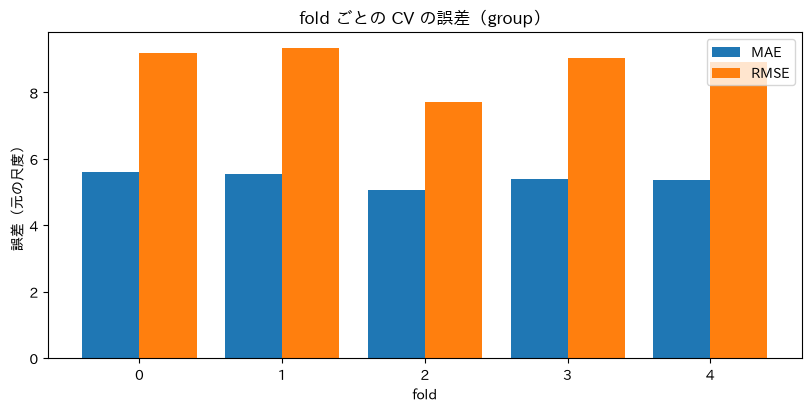

種類ごとの CV の誤差:


,Y_cat,cv_oof_mae,cv_relative_mae
0,Y1,3.3738,0.0568
1,Y2,4.5640,0.0662
2,Y3,9.4591,0.0621
3,Y4,7.9445,0.0603
4,Y5,5.8887,0.0400
5,Y6,4.2106,0.0595
6,Y7,6.5690,0.0606
7,Y8,7.3830,0.0782
8,Y9,3.0357,0.0596
9,Y10,1.5158,0.1025


In [21]:
fold_table = cv_table(run)
scores = cv_result.oof_scores
print(
    f"CV: {CONFIG.CV_METHOD} / 目的変数の変換: {CONFIG.TARGET_TRANSFORM}"
    f" / スケーリング: {CONFIG.FEATURE_SCALING}"
)
print(f"OOF 全体: MAE {scores['mae']:.4f} / RMSE {scores['rmse']:.4f}")
for name in ("MAE", "RMSE"):
    mean, std = fold_table[name].mean(), fold_table[name].std(ddof=0)
    print(f"{name} の fold の平均 ± 標準偏差: {mean:.4f} ± {std:.4f}")
display(fold_table.round(4))
ensure_japanese_font()
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
positions = np.arange(len(fold_table))
ax.bar(positions - 0.2, fold_table["MAE"], 0.4, label="MAE")
ax.bar(positions + 0.2, fold_table["RMSE"], 0.4, label="RMSE")
ax.set_xticks(positions, fold_table["fold"])
ax.set_ylim(bottom=0)  # 棒グラフは0起点
ax.set_xlabel("fold")
ax.set_ylabel("誤差（元の尺度）")
ax.set_title(f"fold ごとの CV の誤差（{CONFIG.CV_METHOD}）")
ax.legend(loc="upper right")
plt.show()
plt.close(fig)
print("種類ごとの CV の誤差:")
summary.round(4)

### 予測の広がり（中央に寄っていないか）

カテゴリごとに、実測と OOF 予測の標準偏差と分位点を比べる（`irregular_flg` が 1 の行は除く）。
**広がりの比**（予測の標準偏差 ÷ 実測の標準偏差）が 1 より小さいほど、予測が中央に寄っている。
`下側の外れ`・`上側の外れ` は、予測が実測の 10% 点を下回る・90% 点を上回る行の割合（中央に寄るほど 0 に近い。
実測と同じ広がりなら 10% 前後）。

In [22]:
normal_rows = run.frame[CONFIG.IRREGULAR_COL].to_numpy() != 1
spread_source = run.oof[(run.oof["fold"] >= 0).to_numpy() & normal_rows]
rows = []
for category, part in spread_source.groupby(CONFIG.CAT_COL, sort=False):
    actual, pred = part[CONFIG.ACTUAL_COL], part[CONFIG.PRED_COL]
    low, high = actual.quantile(0.1), actual.quantile(0.9)
    rows.append(
        {
            CONFIG.CAT_COL: category,
            "実測の標準偏差": actual.std(),
            "予測の標準偏差": pred.std(),
            "広がりの比": pred.std() / actual.std(),
            "下側の外れ": (pred < low).mean(),
            "上側の外れ": (pred > high).mean(),
        }
    )
spread = pd.DataFrame(rows)
print(
    f"広がりの比の平均: {spread['広がりの比'].mean():.3f}（1 に近いほど、予測が実測と同じ広がり）"
)
spread.round(3)

広がりの比の平均: 0.717（1 に近いほど、予測が実測と同じ広がり）


,Y_cat,実測の標準偏差,予測の標準偏差,広がりの比,下側の外れ,上側の外れ
0,Y1,7.961,6.094,0.766,0.055,0.059
1,Y2,7.102,4.293,0.605,0.008,0.025
2,Y3,19.059,13.697,0.719,0.036,0.029
3,Y4,15.569,11.244,0.722,0.037,0.033
4,Y5,13.449,10.674,0.794,0.046,0.064
5,Y6,9.462,7.101,0.750,0.046,0.037
6,Y7,13.069,9.711,0.743,0.049,0.039
7,Y8,11.681,7.148,0.612,0.018,0.019
8,Y9,5.894,4.344,0.737,0.040,0.042
9,Y10,1.823,1.323,0.726,0.025,0.043


### パラメータの最適化（Optuna）

`CONFIG.N_TRIALS` が 1 以上のときの、試行ごとの CV の MAE（元の尺度）と、最良のパラメータ。
最適化に使った CV と同じ CV で評価しているので、上の CV の誤差は楽観的になりやすい。

In [23]:
if run.tuning_trials is None:
    print("Optuna による最適化は行っていません（CONFIG.N_TRIALS = 0）")
else:
    trials = run.tuning_trials
    print(f"試行回数: {len(trials)} / 最良の CV MAE: {trials['value'].min():.4f}")
    print(f"学習に使ったパラメータ: {cv_result.params}")
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    ax.plot(trials["number"], trials["value"], "o", color="C0", label="各試行")
    ax.plot(trials["number"], trials["value"].cummin(), color="C3", label="それまでの最良")
    ax.set_xlabel("試行")
    ax.set_ylabel("CV MAE（元の尺度）")
    ax.set_title("Optuna の最適化の推移")
    ax.legend(loc="upper right")
    plt.show()
    plt.close(fig)
    display(trials.sort_values("value").head(10).round(4))

Optuna による最適化は行っていません（CONFIG.N_TRIALS = 0）


- **カテゴリごとの誤差:** カテゴリごとの CV の相対MAE。
- **学習結果:** カテゴリごとの実測値（黒）と OOF 予測（赤）。`irregular_flg` が 1 の行は、下に外れた点になる。
- **テスト結果:** カテゴリごとの 2025年のモデルの予測（後処理の前。正解が無いので実測は無い）。

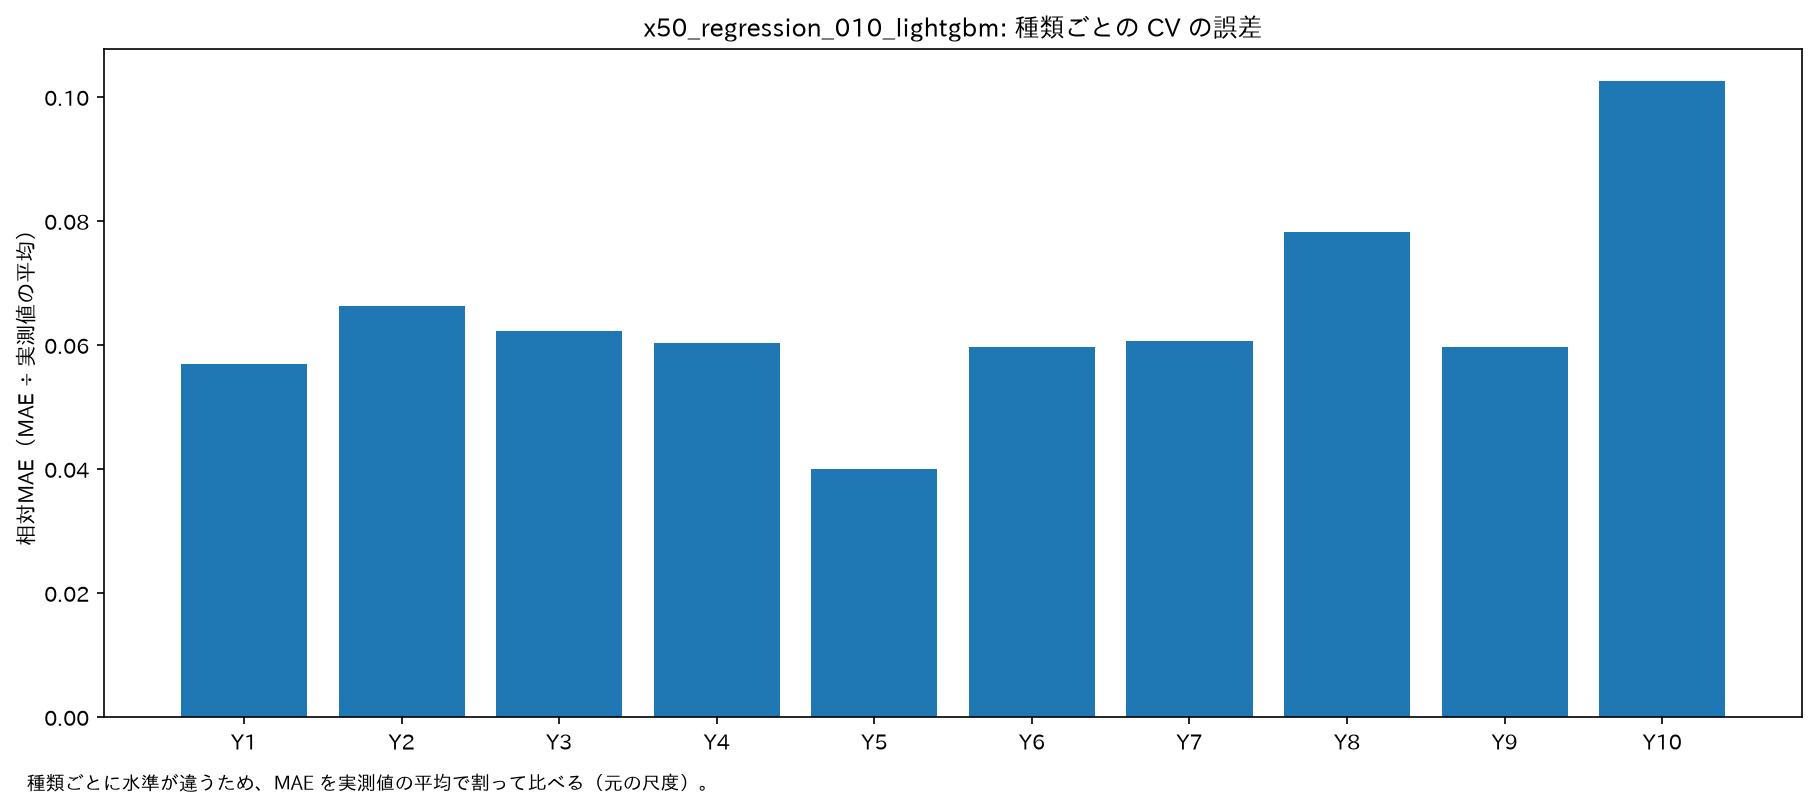

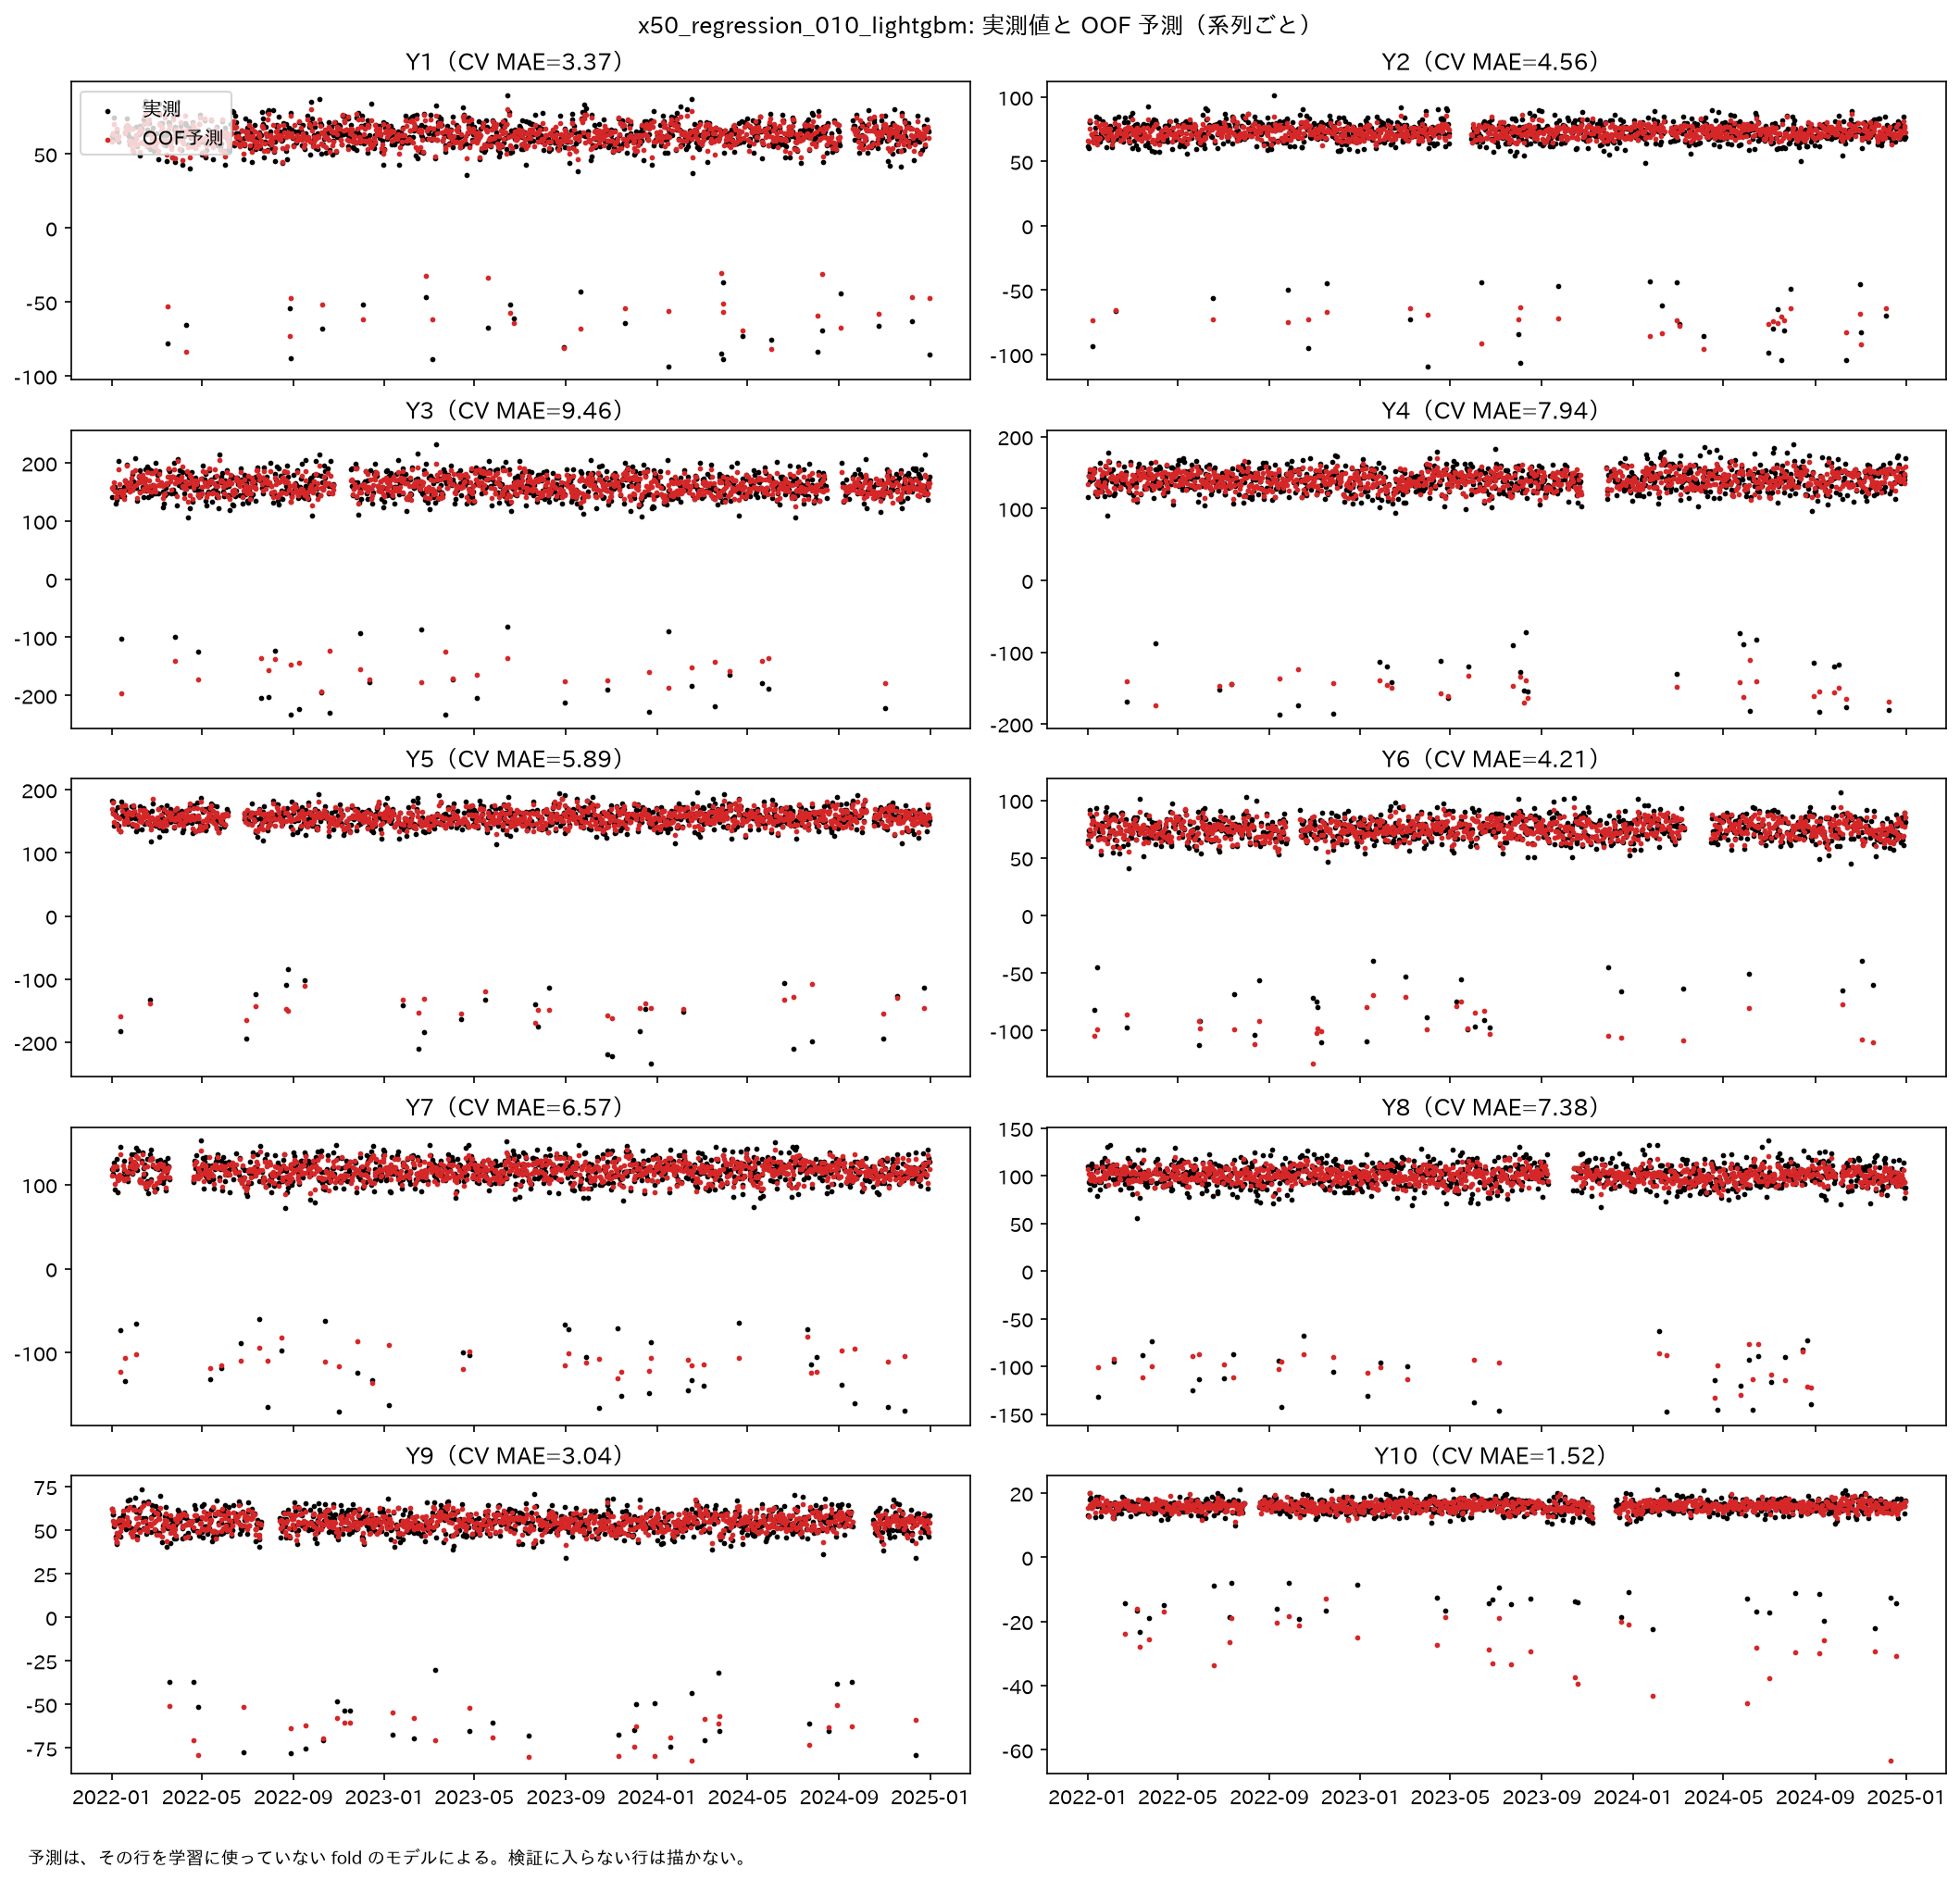

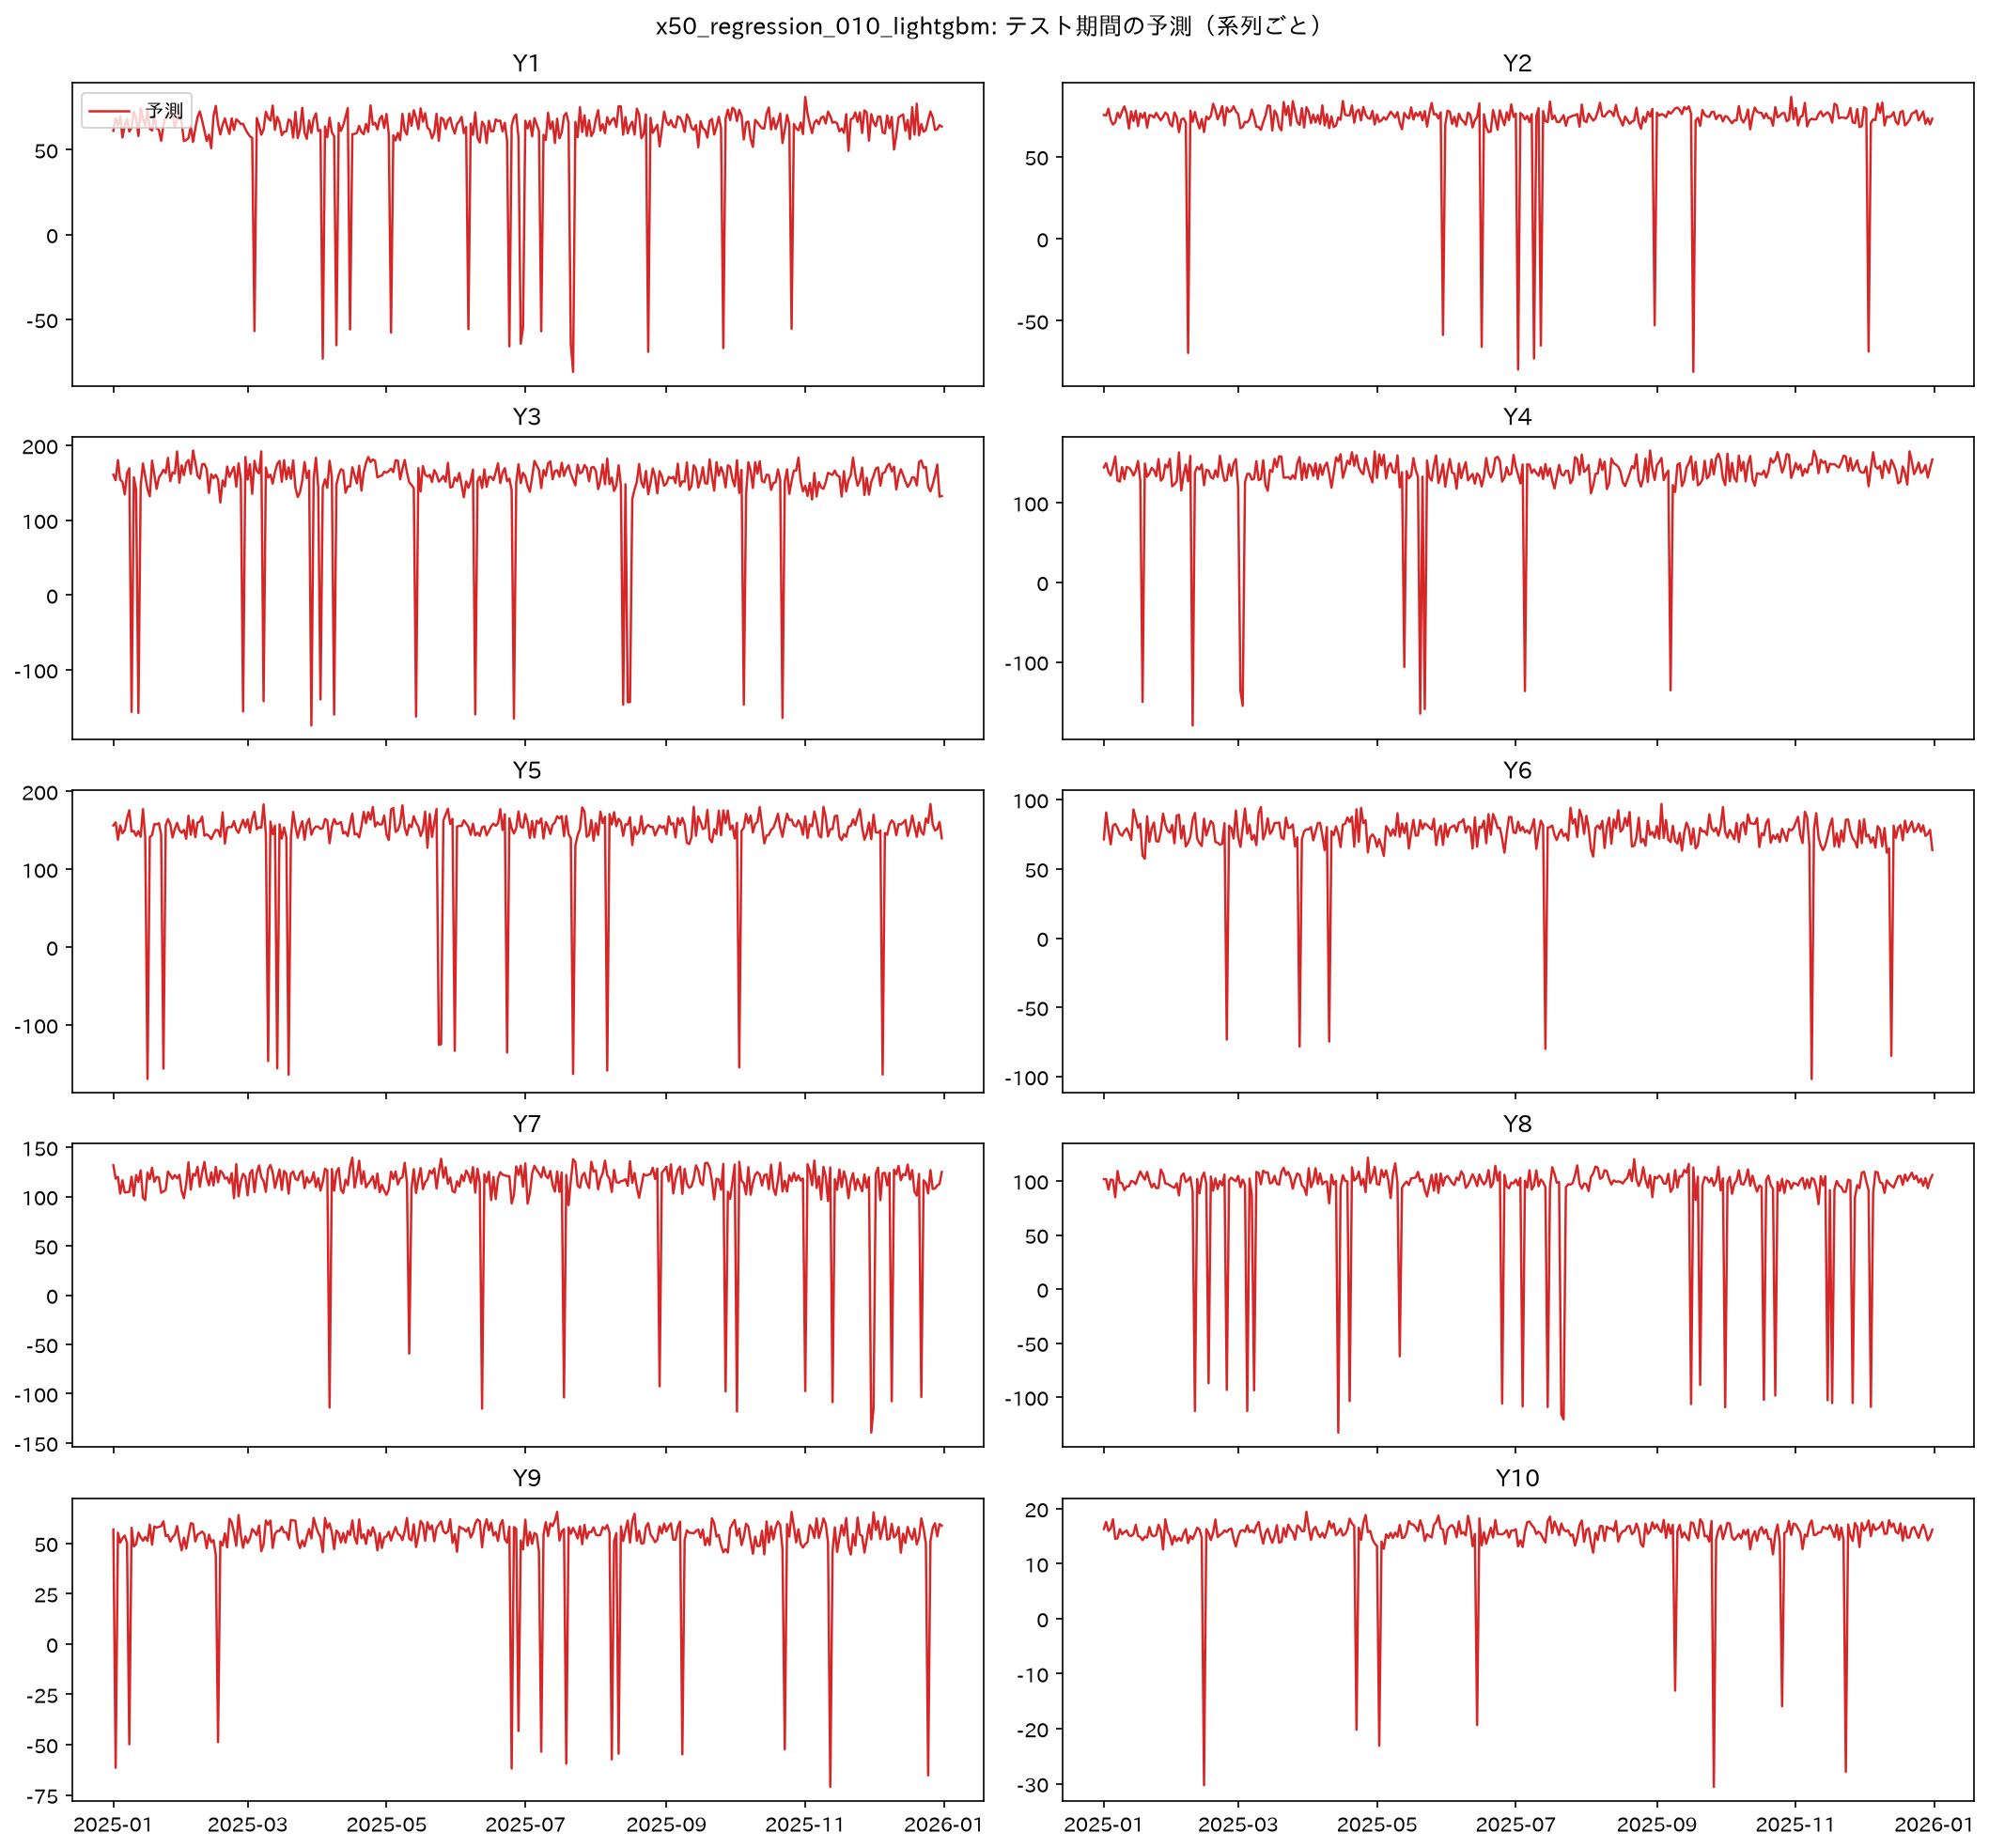

In [24]:
figures = out / "figures"
display(Image(filename=str(figures / "summary_mae.png"), width=950))
display(Image(filename=str(figures / "training_overview.png"), width=1000))
display(Image(filename=str(figures / "test_overview.png"), width=1000))

## 9. SHAP によるモデル解釈

モデルを、各 fold の検証側のデータで説明した SHAP 値（OOF SHAP）。SHAP 値はモデルの尺度（目的変数を変換した場合は
変換後の尺度）。`Y_cat` は系列ID、`irregular_flg` はフラグの特徴量。

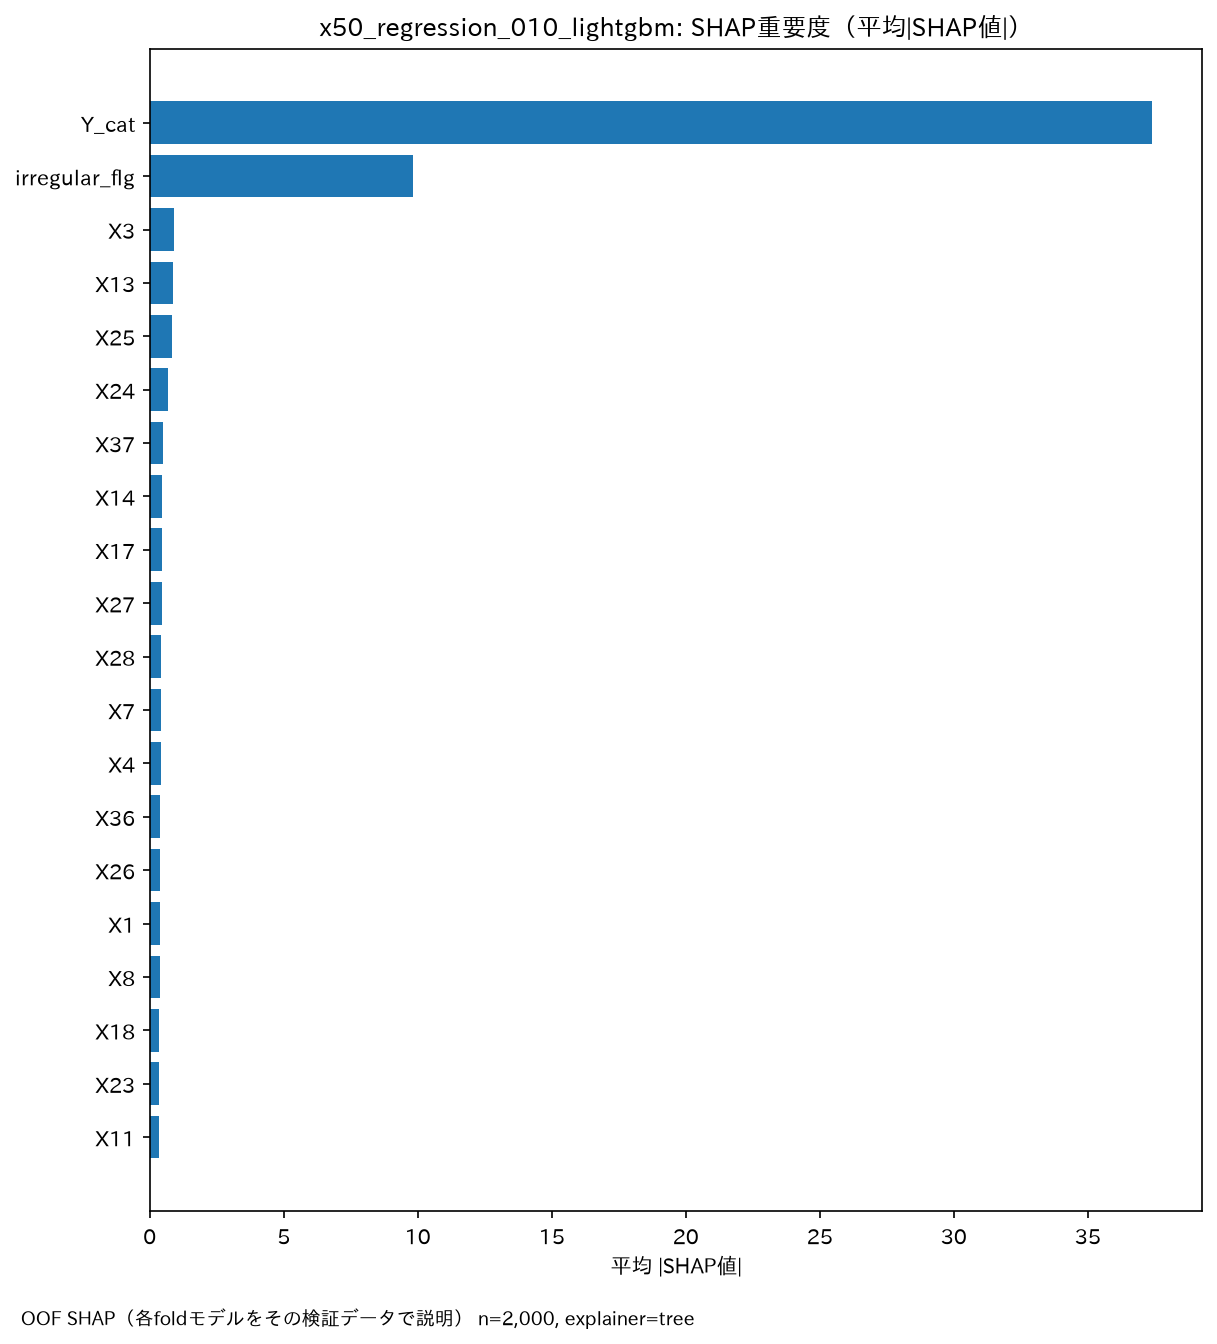

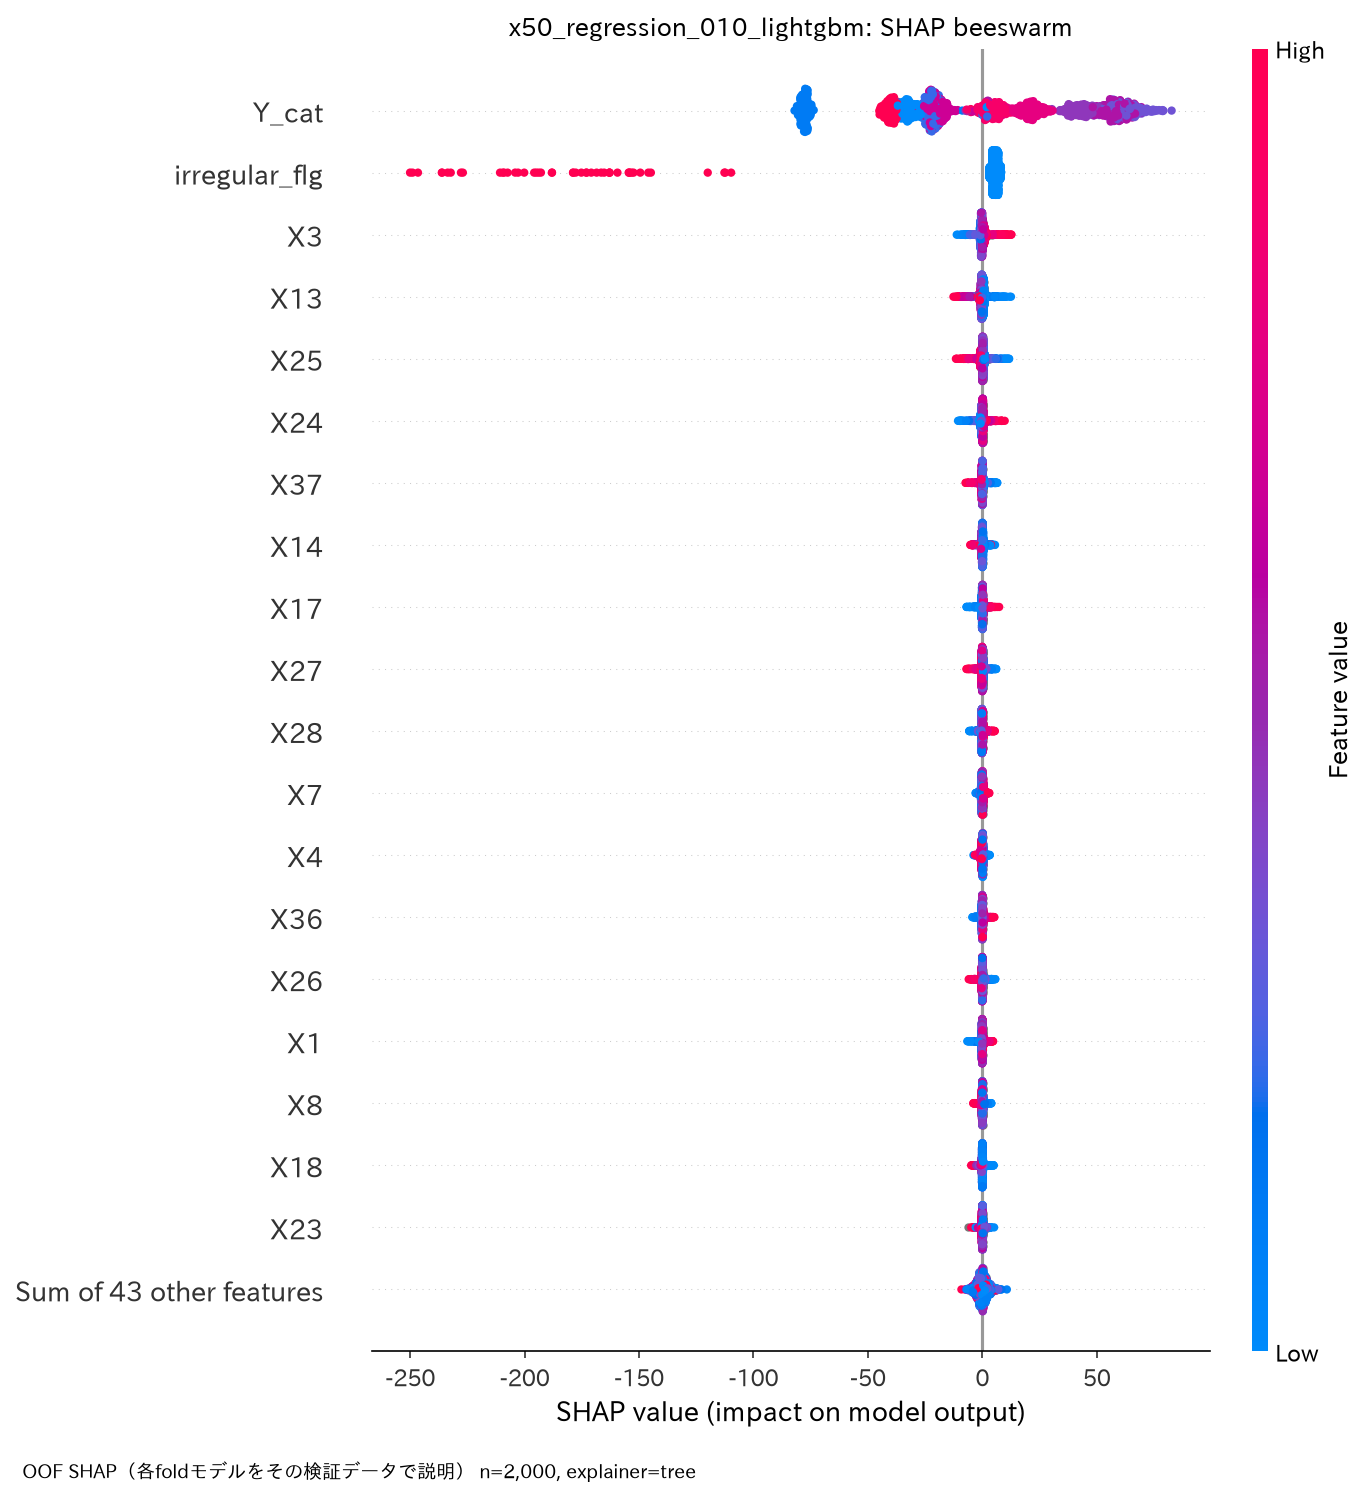

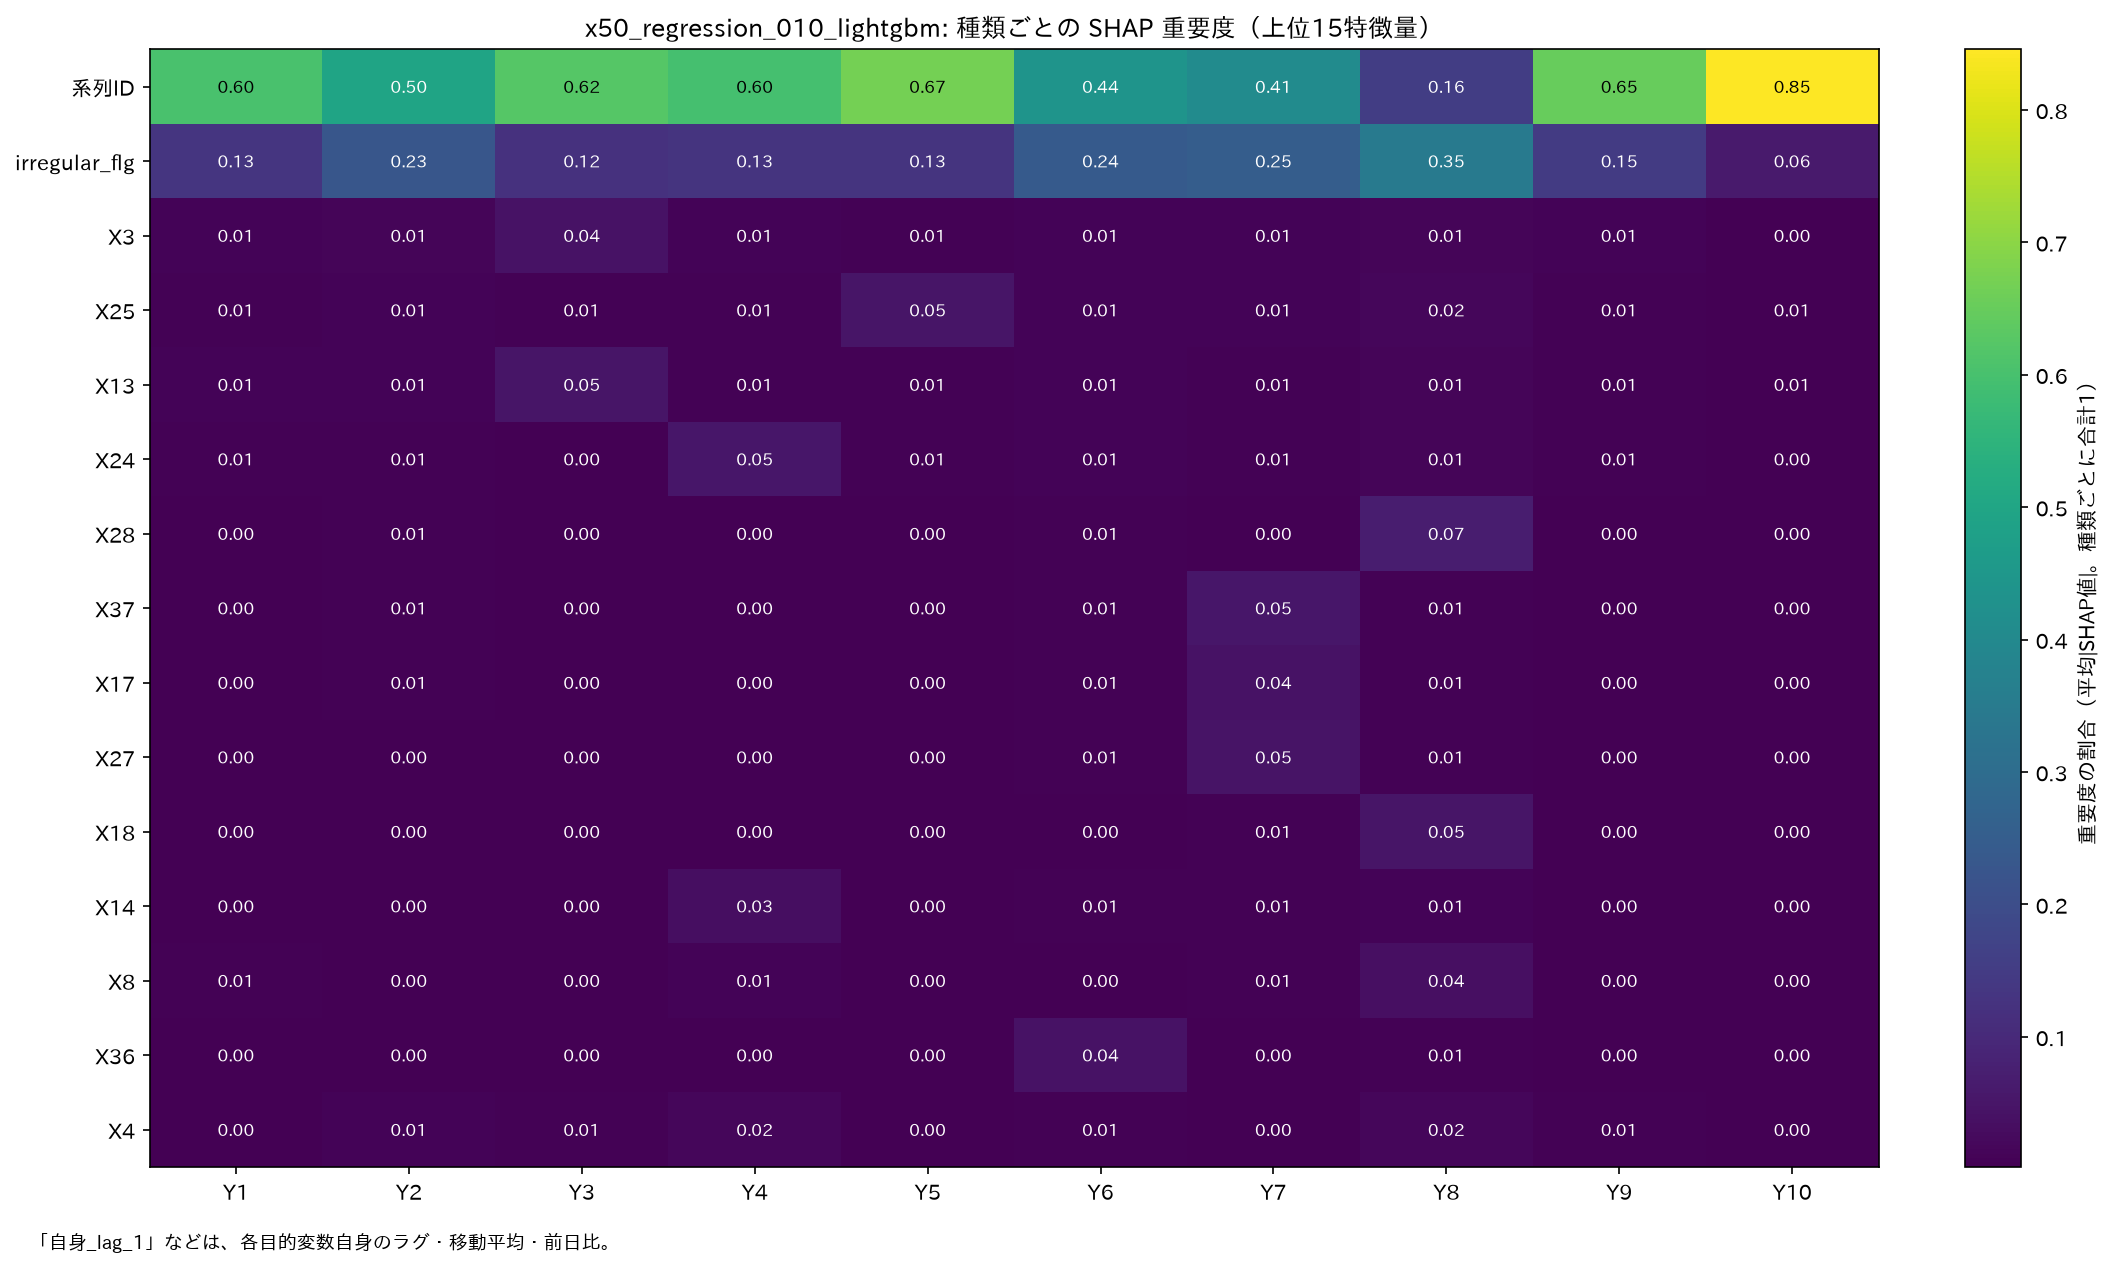

In [25]:
shap_dir = out / "shap"
display(Image(filename=str(shap_dir / "shap_importance_bar.png"), width=700))
display(Image(filename=str(shap_dir / "shap_beeswarm.png"), width=800))
display(Image(filename=str(figures / "shap_overview.png"), width=1000))

## 10. 残差解析

OOF 予測の残差（実測 − 予測。元の尺度、後処理の前）を調べる。`irregular_flg` が 1 の行は通常と違う値なので、残差が
大きく出る。

### 残差の要約

全体とカテゴリごとの、残差の平均（偏り）・標準偏差など。

In [26]:
evaluation_dir = out / EVALUATION_DIR
predicted = run.oof[run.oof["fold"] >= 0]
groups = {
    str(cat): (part[CONFIG.ACTUAL_COL].to_numpy(), part[CONFIG.PRED_COL].to_numpy())
    for cat, part in predicted.groupby(CONFIG.CAT_COL, sort=False)
}
residual_table = pd.DataFrame(
    [
        {
            CONFIG.CAT_COL: "全体",
            **residual_summary(predicted[CONFIG.ACTUAL_COL], predicted[CONFIG.PRED_COL]),
        },
        *[{CONFIG.CAT_COL: cat, **residual_summary(*pair)} for cat, pair in groups.items()],
    ]
)
residual_table.to_csv(evaluation_dir / "residual_summary_by_category.csv", index=False)
display(residual_table.round(4))

,Y_cat,n,mean,std,skewness,excess_kurtosis,mae,rmse
0,全体,10075.0,0.0861,8.8628,-0.4476,23.0158,5.3967,8.8627
1,Y1,1016.0,-0.0494,5.4052,-2.9180,23.5805,3.3738,5.4028
2,Y2,1008.0,0.0812,6.3946,0.1594,9.3111,4.5640,6.3919
3,Y3,1000.0,0.0223,14.5567,-0.6114,14.3506,9.4591,14.5494
4,Y4,1001.0,0.5117,11.5211,1.0238,9.7969,7.9445,11.5267
5,Y5,1015.0,-0.4771,9.6648,-2.5041,25.4581,5.8887,9.6718
6,Y6,999.0,0.5639,7.0107,3.4712,26.6343,4.2106,7.0298
7,Y7,1017.0,-0.2487,9.9331,-1.0787,12.3928,6.5690,9.9313
8,Y8,1018.0,-0.0393,9.8331,-0.6301,3.5842,7.3830,9.8284
9,Y9,999.0,0.1578,4.6081,2.2070,18.9589,3.0357,4.6085


### 誤差曲線

各 fold の、反復（木の本数）ごとの学習・検証の損失。検証の損失が下がらなくなる所で early stopping が止まる。
学習と検証の差が大きいと過学習。モデルの尺度の値。`CONFIG.LEARNING_CURVE = True` なら、学習データの量を変えた
学習曲線も表示する。

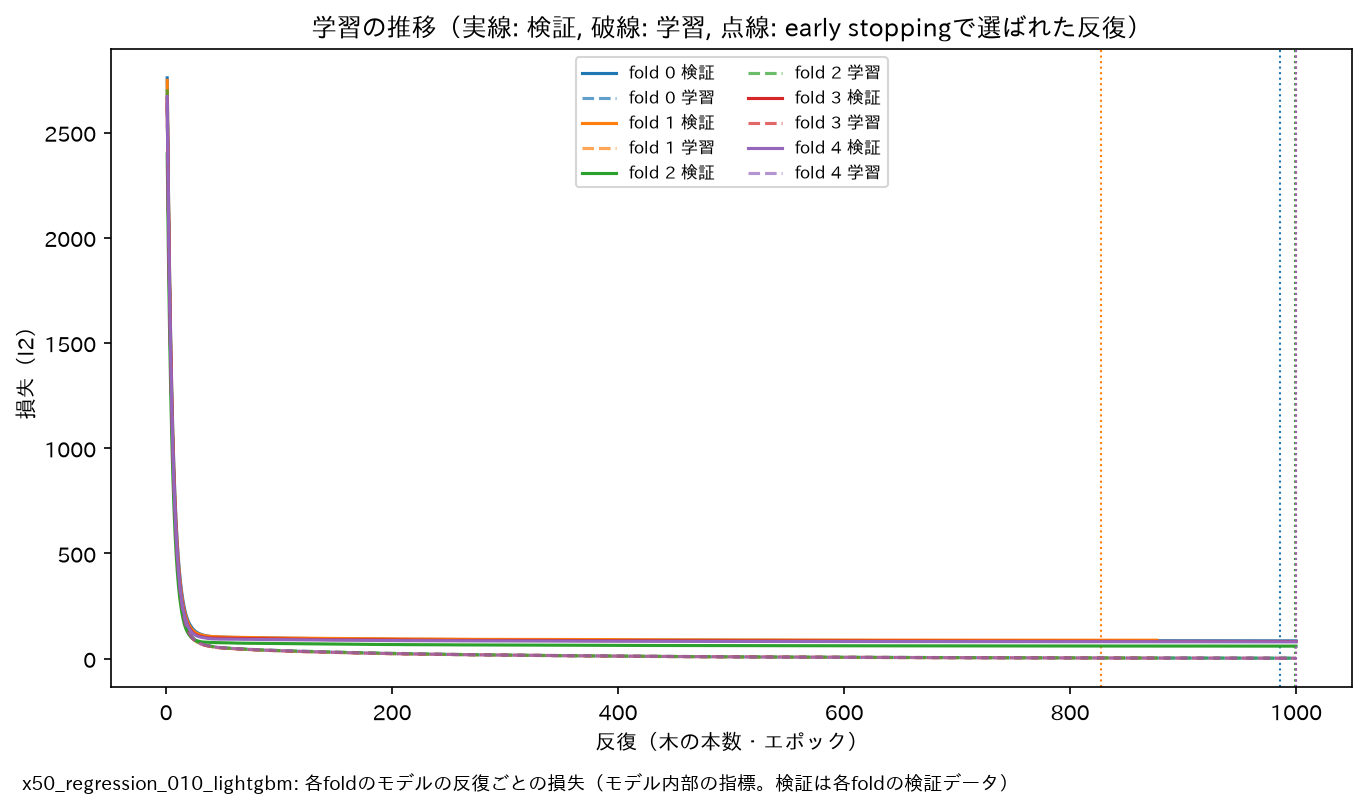

In [27]:
display(Image(filename=str(evaluation_dir / "training_history.png"), width=800))
learning_curve_path = evaluation_dir / "learning_curve.png"
if learning_curve_path.is_file():
    display(Image(filename=str(learning_curve_path), width=800))

### 誤差分布

- **残差の分布:** 山が0からずれていると偏りがある。全体の分布はカテゴリをまとめたものなので、尺度の違いで裾が重く見える。
- **Q-Q プロット:** 点が直線から離れるほど、正規分布から外れている。
- **残差プロット:** 予測値が大きいほど残差が広がるなら、誤差が水準に比例している（対数の変換を試す目安）。
- **カテゴリごとの分布:** 尺度の違いの影響を除いて、カテゴリごとの分布の形を見る。

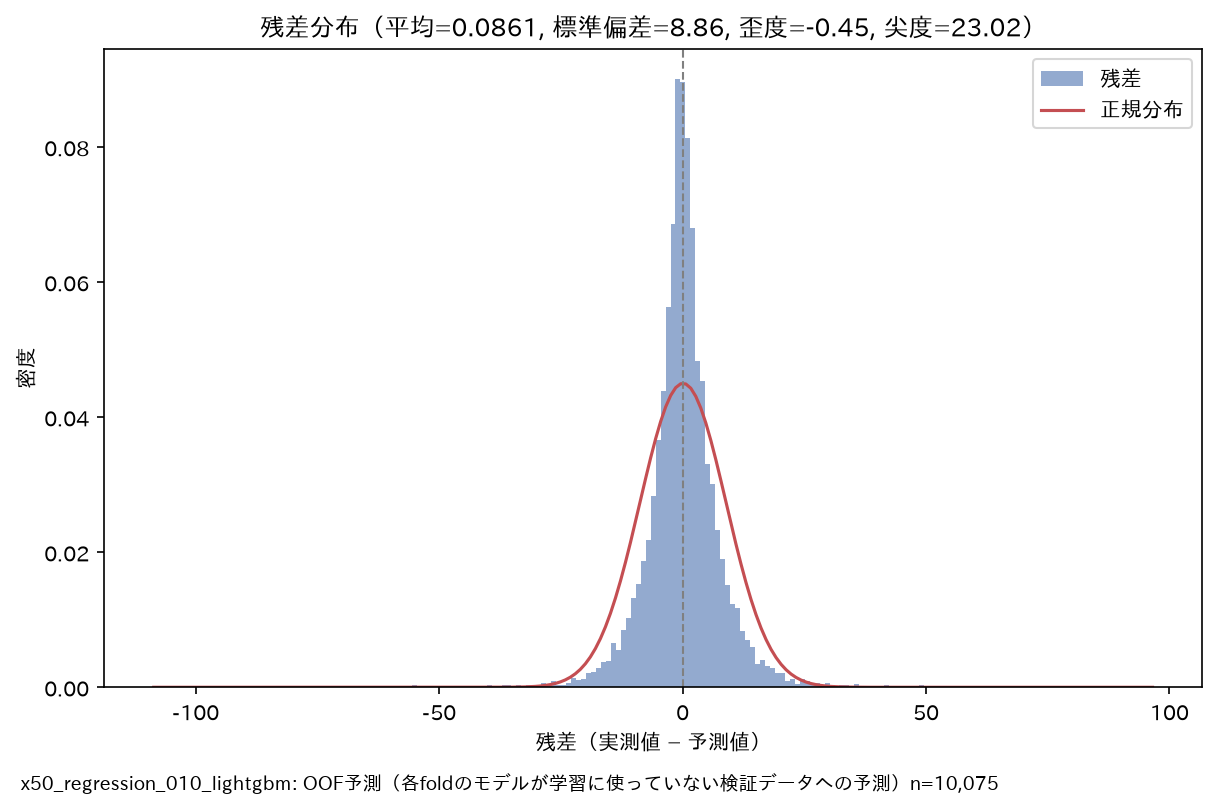

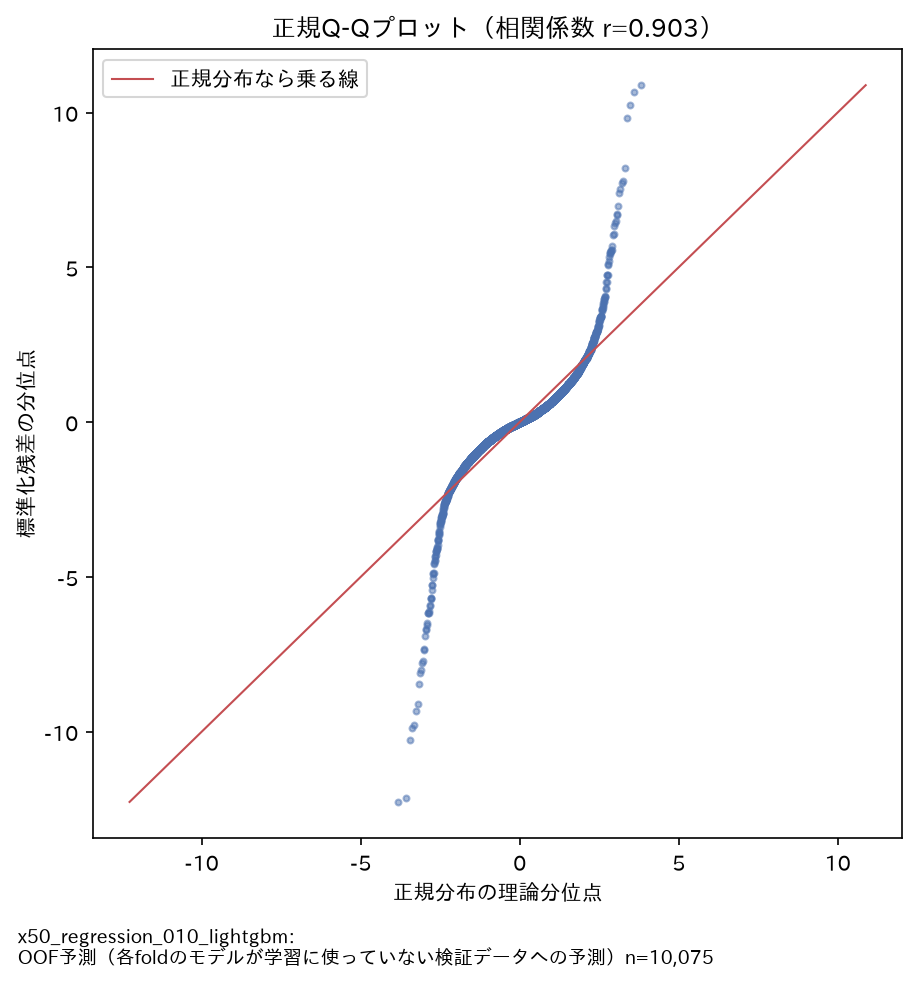

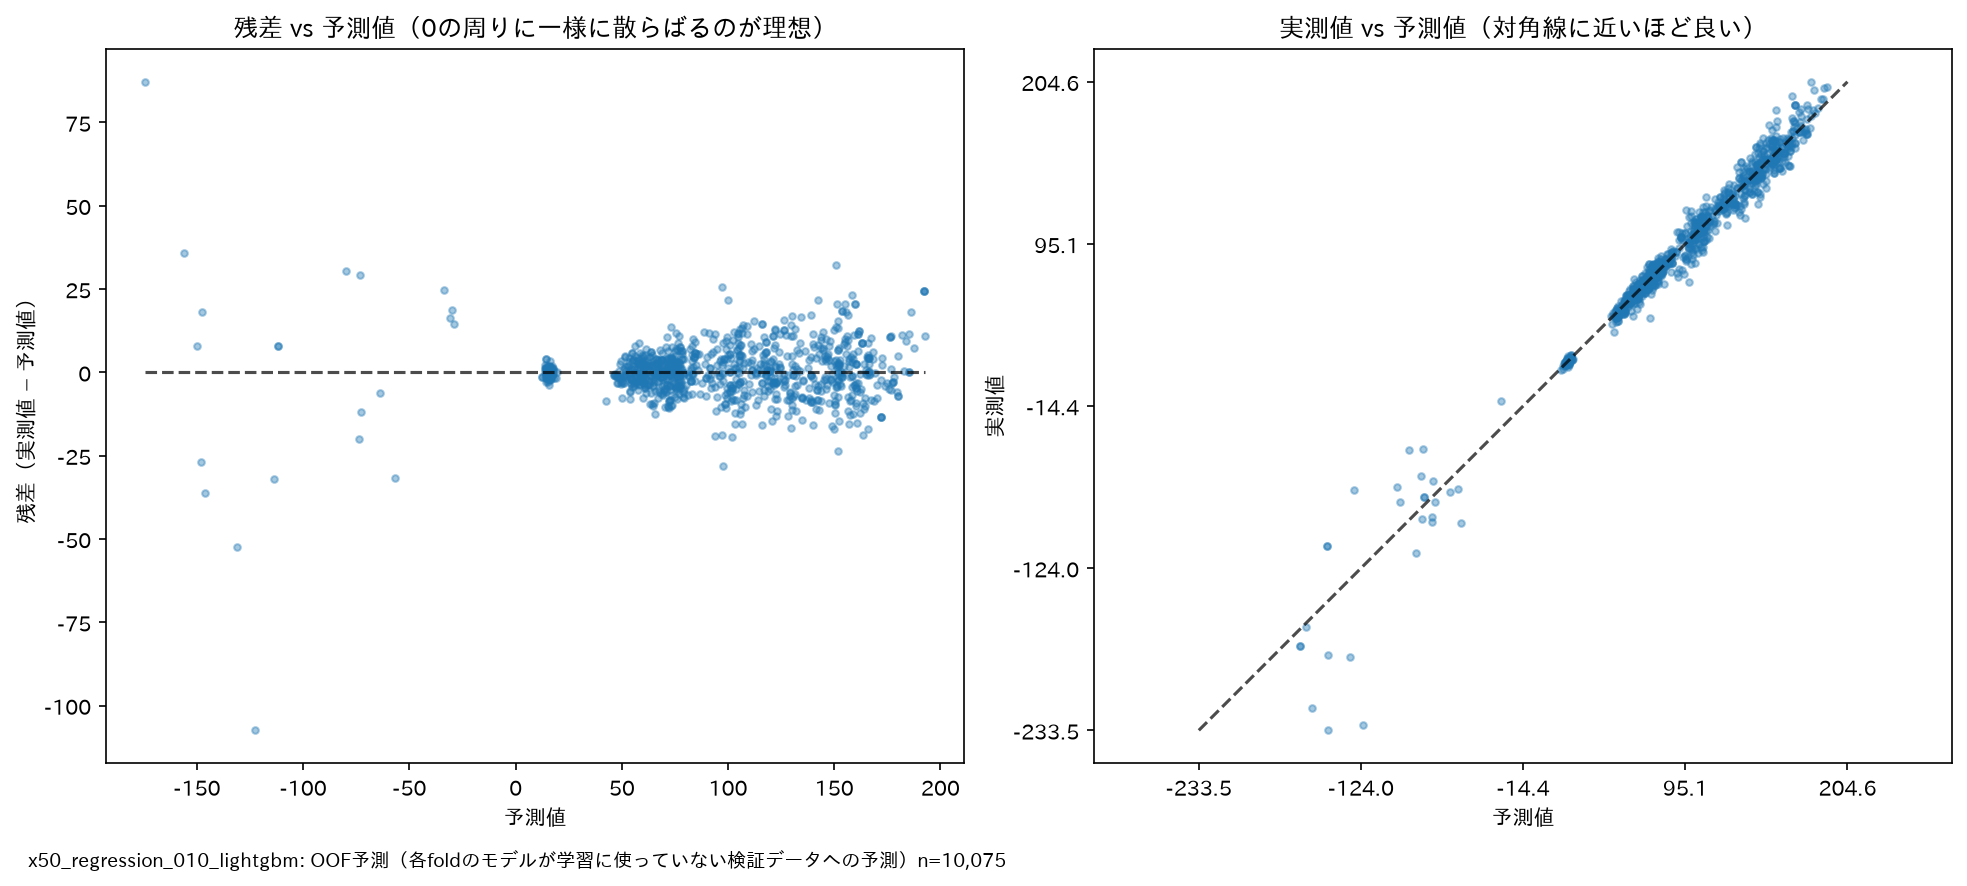

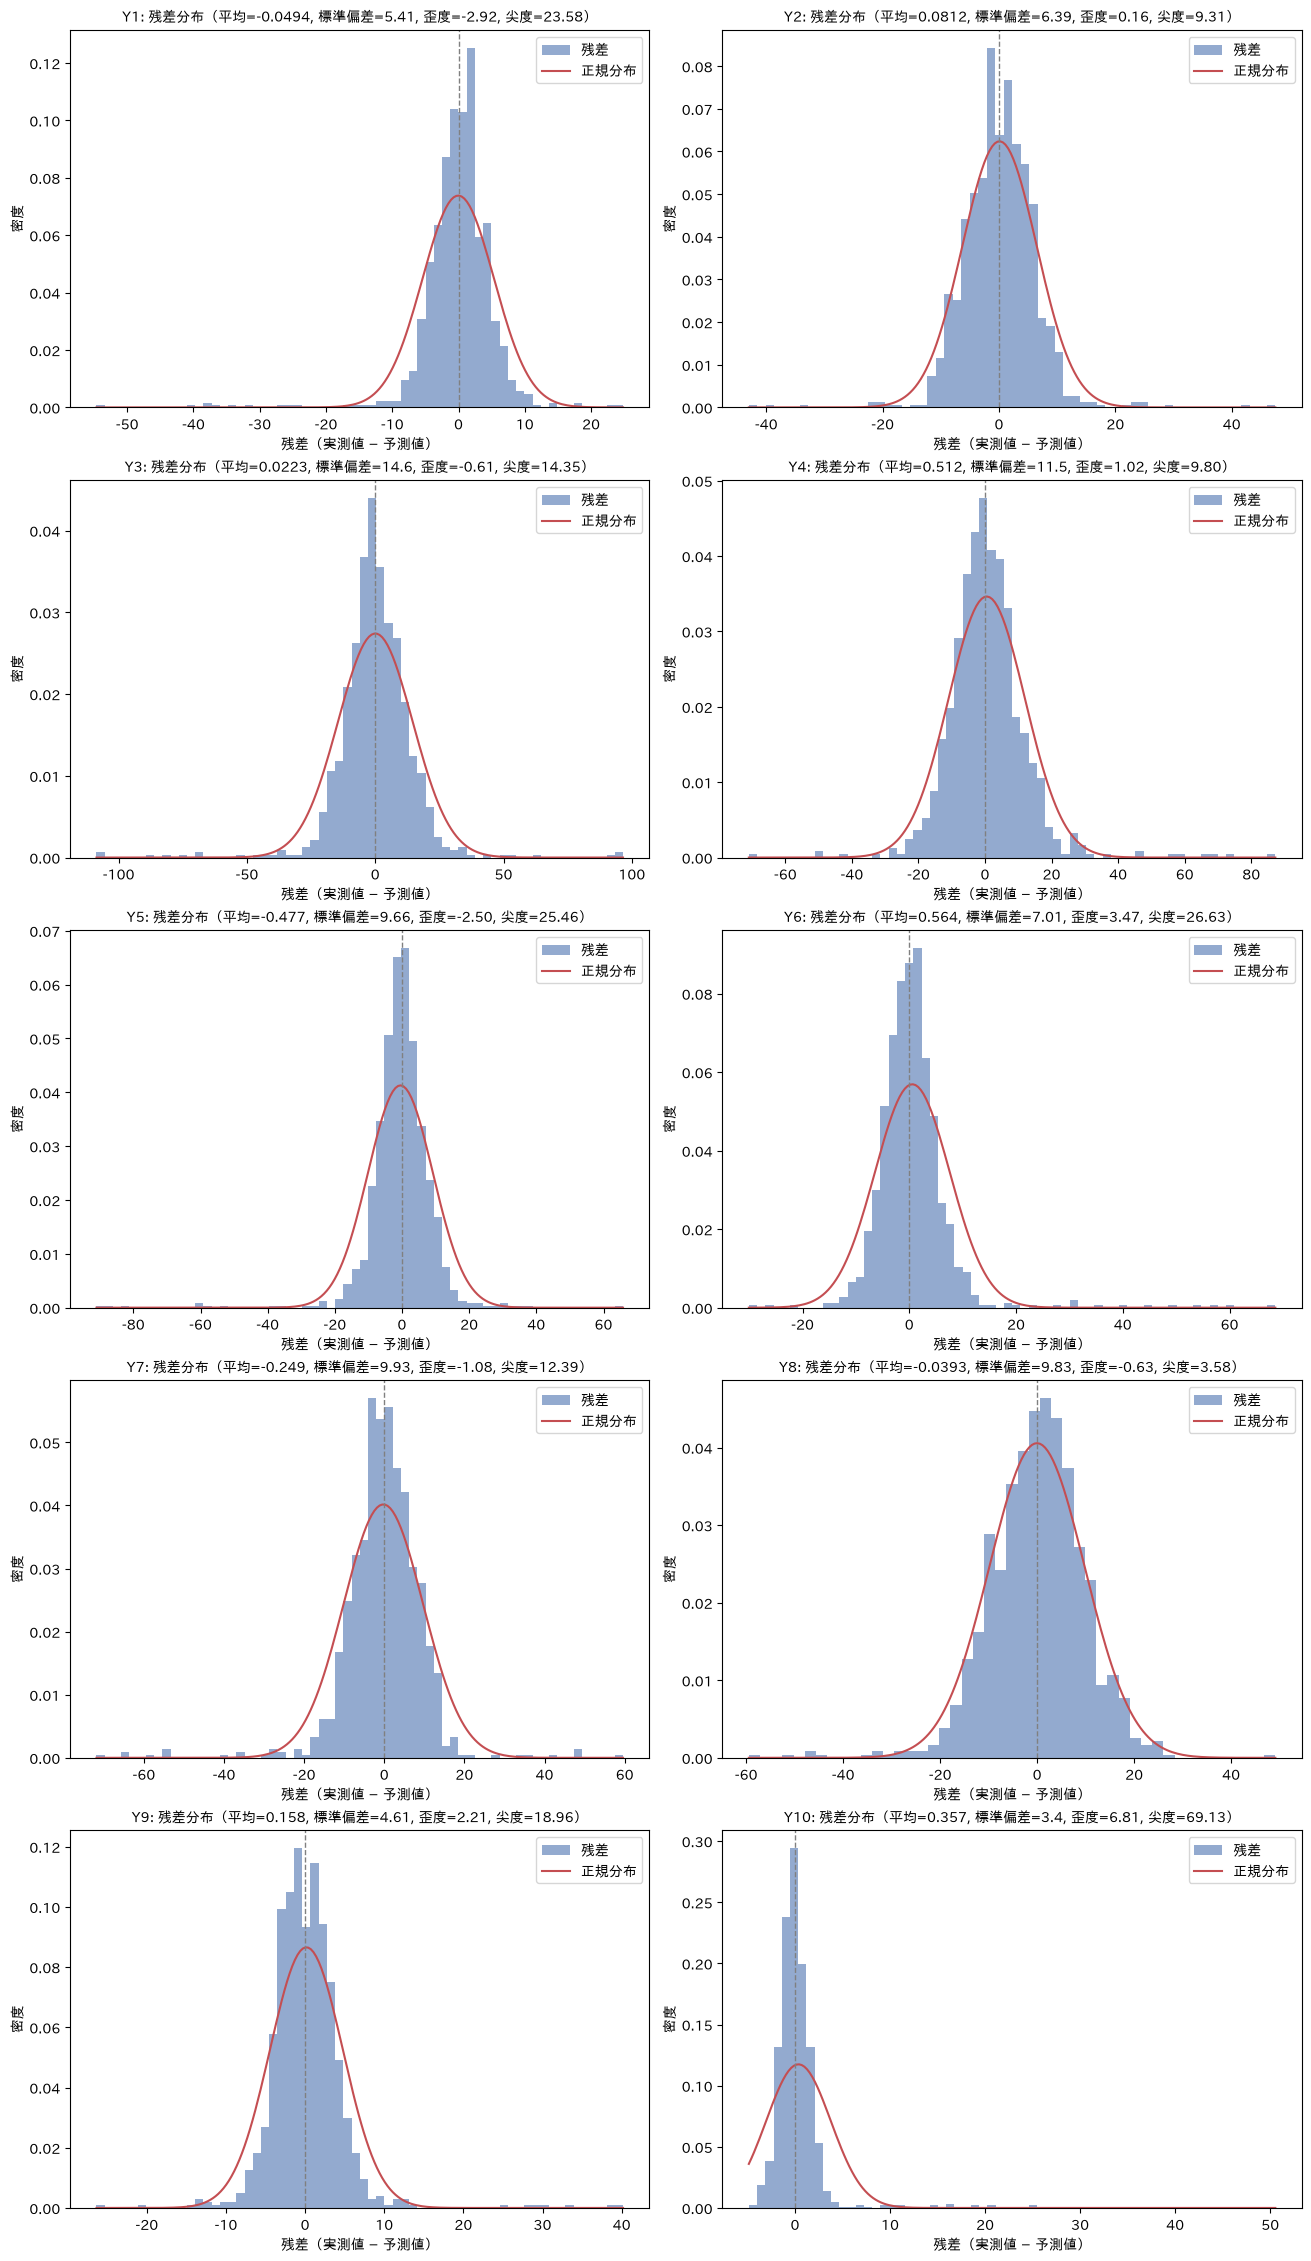

In [28]:
display(Image(filename=str(evaluation_dir / "residual_distribution.png"), width=800))
display(Image(filename=str(evaluation_dir / "qq_plot.png"), width=650))
display(Image(filename=str(evaluation_dir / "residual_plot.png"), width=800))
fig, _ = plot_residuals_by_group("distribution", groups)
fig.savefig(evaluation_dir / "residual_distribution_by_category.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

### 影響の大きい行

Leverage と Cook's distance。線形回帰の診断量なので、木のモデルでは影響の大きい行の目安として見る。

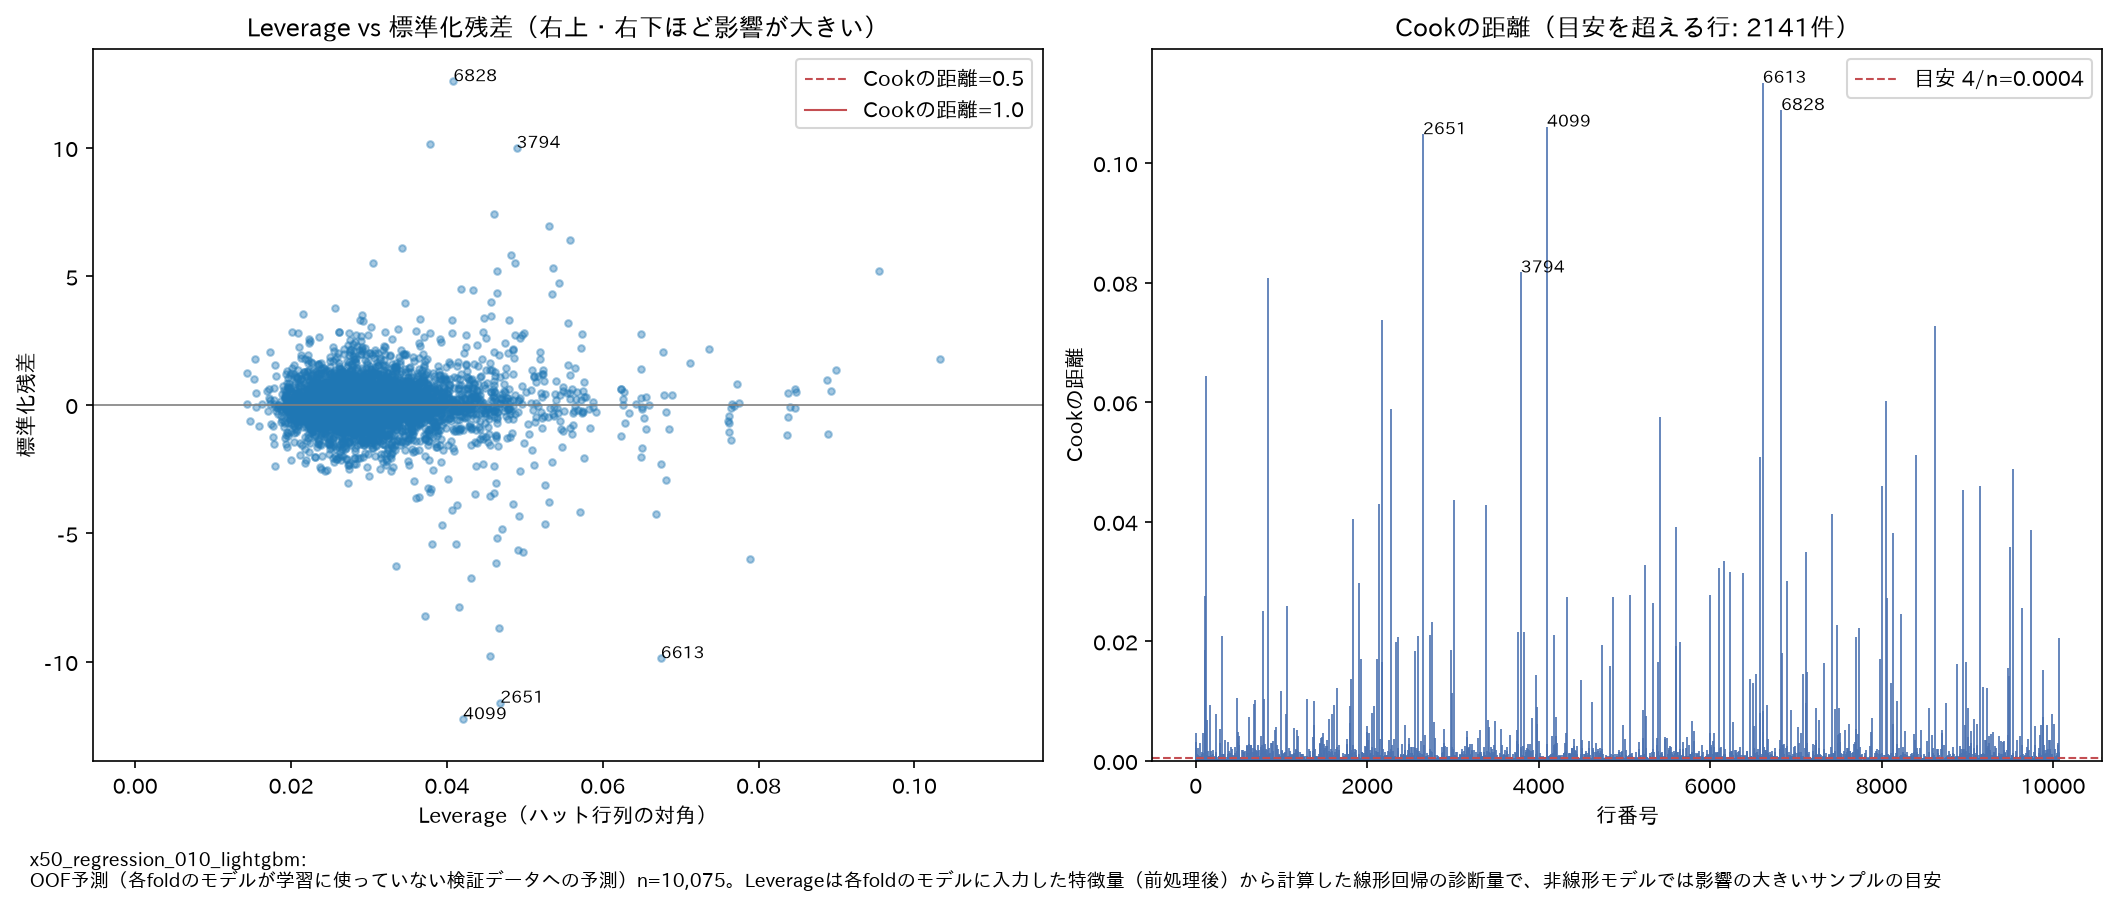

In [29]:
influence_path = evaluation_dir / "leverage_cooks_distance.png"
if influence_path.is_file():
    display(Image(filename=str(influence_path), width=950))

## 11. 1つのカテゴリの詳細（`CONFIG.DETAIL_TARGET`）

残差の推移と自己相関（ACF / PACF）。残差に自己相関が残っていれば、モデルが取りこぼした時間の構造がある。

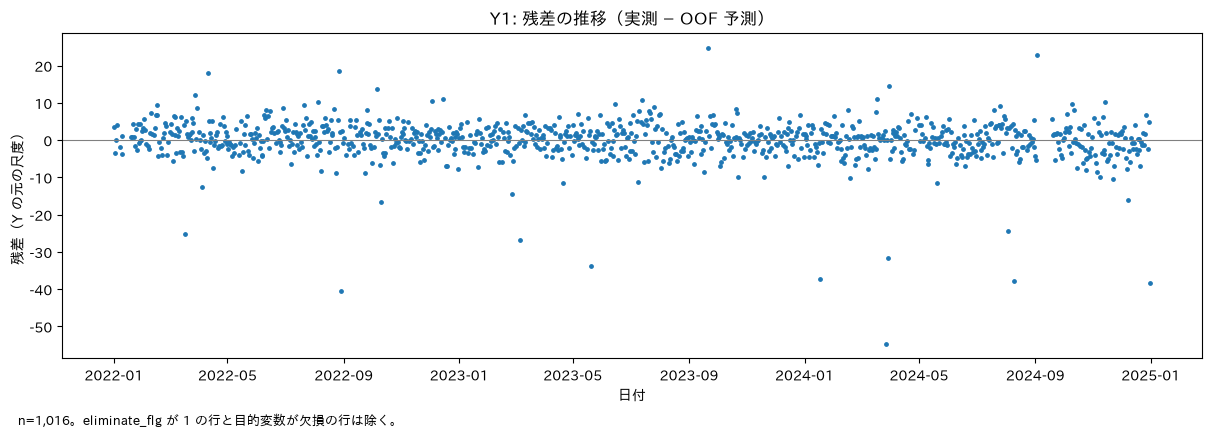

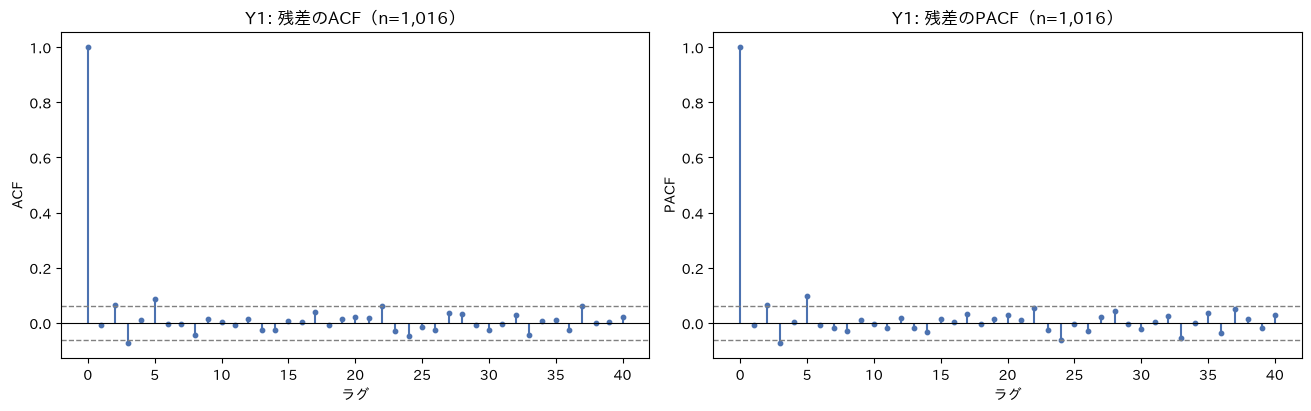

,date,Y_cat,pred
0,2025-01-01,Y1,61.115437
10,2025-01-02,Y1,68.662629
20,2025-01-03,Y1,64.267388
30,2025-01-04,Y1,69.480234
40,2025-01-05,Y1,57.207670


In [30]:
ensure_japanese_font()
detail = predicted[predicted[CONFIG.CAT_COL] == CONFIG.DETAIL_TARGET].sort_values(
    CONFIG.DATE_COL, kind="stable"
)
residuals = detail[CONFIG.ACTUAL_COL] - detail[CONFIG.PRED_COL]
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.scatter(detail[CONFIG.DATE_COL], residuals, s=6, color="C0")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title(f"{CONFIG.DETAIL_TARGET}: 残差の推移（実測 − OOF 予測）")
ax.set_xlabel("日付")
ax.set_ylabel(f"残差（{CONFIG.TARGET_COL} の元の尺度）")
add_caption(fig, f"n={len(detail):,}。eliminate_flg が 1 の行と目的変数が欠損の行は除く。")
plt.show()
plt.close(fig)
correlogram = ResidualCorrelogramDisplay.from_residuals(
    {CONFIG.DETAIL_TARGET: residuals.to_numpy()}
)
plt.show()
plt.close(correlogram.figure_)
run.predictions[run.predictions[CONFIG.CAT_COL] == CONFIG.DETAIL_TARGET].head()

## 12. 後処理（上下限のクリップ・`irregular_flg` の行を0にする）

モデルの予測の後に、次の順で後処理をかける（モデル・CV のスコアには含めない）。

1. カテゴリごとの上下限（`CONFIG.TARGET_BOUNDS`。無いカテゴリは `CONFIG.DEFAULT_TARGET_BOUNDS`）で、予測値をクリップする。
2. テストデータの `irregular_flg` が 1 の行は、予測値を強制的に 0 にする（上下限より優先する）。

下の表は、カテゴリごとの上下限と、クリップした行数・0 にした行数。

In [31]:
bounds = target_bounds(cats)
final = postprocess(run.predictions, test_raw, bounds)
counts = final.groupby(CONFIG.CAT_COL, sort=False).agg(
    **{
        "行数": (CONFIG.PRED_COL, "size"),
        "クリップした行数": ("clipped", "sum"),
        "0にした行数": ("zeroed", "sum"),
    }
)
display(bounds.set_index(CONFIG.CAT_COL).join(counts).loc[cats])
# 後処理が決まりどおりか確かめる
assert (final.loc[final["zeroed"], CONFIG.PRED_COL] == 0).all()
inside = final.loc[~final["zeroed"]].merge(bounds, on=CONFIG.CAT_COL)
assert (inside[CONFIG.PRED_COL] >= inside["lower"].fillna(-np.inf)).all()
assert (inside[CONFIG.PRED_COL] <= inside["upper"].fillna(np.inf)).all()
print(
    f"OK: {CONFIG.IRREGULAR_COL} = 1 の {int(final['zeroed'].sum())}行は 0、"
    "それ以外は上下限の範囲内"
)

,lower,upper,行数,クリップした行数,0にした行数
Y_cat,,,,,
Y1,0.0,NaN,365,0,15
Y2,0.0,NaN,365,0,9
Y3,0.0,NaN,365,0,15
Y4,0.0,NaN,365,0,9
Y5,0.0,NaN,365,0,13
Y6,0.0,NaN,365,0,6
Y7,0.0,NaN,365,0,13
Y8,0.0,NaN,365,0,22
Y9,0.0,NaN,365,0,13


OK: irregular_flg = 1 の 123行は 0、それ以外は上下限の範囲内


## 13. テストデータの予測の出力

後処理の後のテスト予測を `outputs/predictions/` に CSV で出力する。列は `ID`（0から始まる連番）、`date`（日付）、
`Y_cat`（目的変数のカテゴリ）、`pred`（予測値。元の尺度・後処理の後）の順で、行は目的変数のカテゴリ、日付の順に昇順。
カテゴリは番号の順（Y1, Y2, …, Y10）に並べる。テストデータの全行を含む。

In [32]:
prediction_table = test_prediction_table(final, cats)
assert len(prediction_table) == len(test_raw), "テストデータの全行がありません"
assert not prediction_table.duplicated([CONFIG.DATE_COL, CONFIG.CAT_COL]).any(), (
    "予測の行が重複しています"
)
prediction_path = ensure_parent_dir(
    outputs_dir() / CONFIG.PREDICTIONS_DIR / f"{config.name}_{stamp}.csv"
)
prediction_table.to_csv(prediction_path, index=False, date_format="%Y-%m-%d")
print(f"テスト予測: {shown(prediction_path)}（{len(prediction_table)}行）")
display(prediction_table.head())
prediction_table.tail()

テスト予測: outputs/predictions/x50_regression_010_lightgbm_20261104_032530.csv（3650行）


,ID,date,Y_cat,pred
0,0,2025-01-01,Y1,61.115437
1,1,2025-01-02,Y1,68.662629
2,2,2025-01-03,Y1,64.267388
3,3,2025-01-04,Y1,69.480234
4,4,2025-01-05,Y1,57.207670


,ID,date,Y_cat,pred
3645,3645,2025-12-27,Y10,17.101731
3646,3646,2025-12-28,Y10,15.970082
3647,3647,2025-12-29,Y10,14.242130
3648,3648,2025-12-30,Y10,14.971193
3649,3649,2025-12-31,Y10,16.203125


## まとめ

- 設定は2セル目の `CONFIG` にまとめ、コードは `CONFIG.名前` で参照した。
- 学習データの `eliminate_flg` が 1 の行は学習に使わず、`irregular_flg` は特徴量として使った。目的変数のラグ・移動平均は
  作っていない。
- 説明変数のスケーリングと目的変数の変換は、CV の fold ごとに学習側だけで fit した。CV のスコアと残差は元の尺度で、
  後処理を含まないモデルの予測の誤差。
- テスト予測には後処理（カテゴリごとの上下限のクリップ、`irregular_flg` が 1 の行を 0）をかけ、`outputs/predictions/` に
  CSV で出力した。

**注意点**

- テストの正解が無いので、テストの誤差は計算していない。評価は CV だけで行っている。
- GroupKFold では検証の月より後の月も学習に使うため、CV は学習データより後の期間の予測より楽観的になりやすい。
- 学習データの `irregular_flg` が 1 の行は、通常と違う値（ダミーでは負の値）なので、CV の誤差・残差を大きくする。
  テストではその行を 0 にするので、CV の誤差はテストの誤差の目安として悪めに出る。
- 学習の推移（誤差曲線）と SHAP は、モデルの尺度（目的変数を変換した後の尺度）。残差の表・図は元の尺度。
- `irregular_flg` が 1 の行に負の値があるデータでは、目的変数の対数の変換は使えない（エラーで止まる）。